# Final Parcel-Based Corridors2 for Oakland

**Goal.** Take the rough hand-drawn corridor polygons exported from Google My Maps
(`data/geo/corridors2_drawing.gpkg`) and produce ONE final, coherent set of parcel-informed, *continuous* corridor
polygons: `data/corridors/corridors2/corridors2_final.gpkg`.

**Workflow in two stages**

1. **Candidate stage (Sections 1-9, largely unchanged).** From an Oakland-only parcel subset, three parcel-based candidates
   are generated for every drawing (`MAXIMAL`, `COMMERCIAL`, `COMMERCIAL_COMPLETED`), each with conservative street-gap filling.
   The candidate GeoPackages are still exported for QGIS comparison, but they are no longer the focus.
2. **Final stage (Sections 10-15).** For each corridor we take the candidate that was judged closest to the intended footprint
   (`MAXIMAL` for eight corridors, `COMMERCIAL_COMPLETED` for Fruitvale, Havencourt and Elmhurst) and apply **corridor-specific
   continuity rules** defined in `CORRIDOR_FINAL_CONFIG`: a modest morphological closing, bridging of remaining road/space gaps between
   components, and removal of tiny isolated fragments. Corridors judged good are carried through unchanged.

**Principles.** The hand drawings define *intent*; parcels define physical boundaries; streets and narrow gaps are absorbed so each corridor reads as one
geography (like the existing BIDs and Policy Polygons); corridors are **never** made mutually exclusive; no single aggressive global buffer is applied; and a
corridor that cannot be connected without an absurd bridge stays a small MultiPolygon, with the reason documented.

The existing `OAK_BIDs` and `Policy_Polygons` layers are used **only as a visual/structural yardstick**; they never clip or constrain the new corridors.

## Code Cell 1 -- Imports

All imports live in this one cell.

In [1]:
import re
import itertools
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from shapely.geometry import Polygon
import pyogrio

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from tqdm.notebook import tqdm

warnings.filterwarnings("ignore", message=".*winding order.*")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## Code Cell 2 -- Paths, Constants and Parameters

Every path, CRS, field name, threshold, tolerance and output filename lives here. The geometric tolerances
(gap-closing distance, drawing buffer, hole/fragment sizes) are **justified empirically in Sections 4 and 6**
before being relied upon.

In [2]:
# ---------------------------------------------------------------------------
# Input paths (read-only)
# ---------------------------------------------------------------------------
ROOT = Path("/home/aniket/Programming/eddit-east-bay")

DRAWING_GPKG = ROOT / "data/geo/corridors2_drawing.gpkg"
PARCELS_SHP = ROOT / "data/geo/Parcels_7711352183771741448/Parcel_Boundaries.shp"
OAKLAND_BOUNDARY_GPKG = ROOT / "data/geo/oakland_boundary.gpkg"
PARCEL_SUBSET_DIR = ROOT / "data/geo/parcels_subset"
SUBSET_USE_CODE_GPKG = PARCEL_SUBSET_DIR / "parcels_use_code_filtered.gpkg"
SUBSET_BUSINESS_GPKG = PARCEL_SUBSET_DIR / "parcels_with_business.gpkg"
SUBSET_UNION_GPKG = PARCEL_SUBSET_DIR / "parcels_union.gpkg"      # use-code OR business
BIDS_SHP = ROOT / "data/corridors/OAK_BIDs/OAK_BIDs.shp"
POLICY_SHP = ROOT / "data/corridors/Policy_Polygons/Policy_Polygons.shp"

# ---------------------------------------------------------------------------
# Output paths (this notebook writes ONLY these)
# ---------------------------------------------------------------------------
OAKLAND_PARCELS_GPKG = PARCEL_SUBSET_DIR / "oakland_parcels.gpkg"
OAKLAND_PARCELS_LAYER = "oakland_parcels"

OUT_DIR = ROOT / "data/corridors/corridors2_candidates"
OUT_LAYER = "corridors"
OUT_ALL_LAYER = "all_candidates"
OUT_SELECTED_LAYER = "selected_parcels"
OUT_MAXIMAL = OUT_DIR / "corridors2_maximal.gpkg"
OUT_COMMERCIAL = OUT_DIR / "corridors2_commercial.gpkg"
OUT_COMPLETED = OUT_DIR / "corridors2_commercial_completed.gpkg"
OUT_ALL = OUT_DIR / "corridors2_all_candidates.gpkg"
OUT_SELECTED_PARCELS = OUT_DIR / "corridors2_selected_parcels.gpkg"
# Final layer
FINAL_DIR = ROOT / "data/corridors/corridors2"
FINAL_GPKG = FINAL_DIR / "corridors2_final.gpkg"
FINAL_LAYER = "corridors"
FINAL_SELECTED_PARCELS_GPKG = FINAL_DIR / "corridors2_final_selected_parcels.gpkg"
FINAL_SELECTED_LAYER = "selected_parcels"
SELECTED_PARCELS_MAX_MB = 100          # only write the QA parcel file if it stays below this size

# ---------------------------------------------------------------------------
# CRS
# ---------------------------------------------------------------------------
CRS_METRIC = "EPSG:26910"   # NAD83 / UTM 10N (metres): ALL area / distance work
CRS_EXPORT = "EPSG:4326"    # exported corridor / QA files (web mapping + QGIS friendly)

# ---------------------------------------------------------------------------
# Field names
# ---------------------------------------------------------------------------
DRAWING_NAME_FIELD = "Name"
PARCEL_ID_FIELD = "APN"
USE_CODE_FIELD = "UseCode"
# Columns kept in the Oakland parcel subset (mailing-address / document fields dropped to keep it small)
OAKLAND_PARCEL_COLUMNS = [
    "APN", "BOOK", "PAGE", "PARCEL", "SUB_PARCEL", "CLCA_CATEG", "SitusStree", "SitusStr_1", "SitusUnit",
    "SitusCity", "SitusZip", "SitusAddre", "Land", "Imps", "TotalNetVa", "UseCode",
]
COMMERCIAL_USE_CODE_PREFIXES = ("3", "8", "9")   # the use-code definition behind parcels_use_code_filtered

# ---------------------------------------------------------------------------
# Corridor / candidate naming
# ---------------------------------------------------------------------------
CORRIDOR_ID_PREFIX = "c2_"
METHOD_MAXIMAL = "MAXIMAL"
METHOD_COMMERCIAL = "COMMERCIAL"
METHOD_COMPLETED = "COMMERCIAL_COMPLETED"
METHODS = [METHOD_MAXIMAL, METHOD_COMMERCIAL, METHOD_COMPLETED]
METHOD_COLORS = {METHOD_MAXIMAL: "#1b6ca8", METHOD_COMMERCIAL: "#d95f02", METHOD_COMPLETED: "#2a9d3f"}
METHOD_OUT_FILES = {METHOD_MAXIMAL: OUT_MAXIMAL, METHOD_COMMERCIAL: OUT_COMMERCIAL, METHOD_COMPLETED: OUT_COMPLETED}

# ---------------------------------------------------------------------------
# Parcel selection thresholds
# ---------------------------------------------------------------------------
PARCEL_OVERLAP_THRESHOLD = 2 / 3        # MAXIMAL: intersection_area / PARCEL area
COMMERCIAL_OVERLAP_THRESHOLD = 2 / 3    # COMMERCIAL: same rule, applied to commercial/business parcels only
NEAR_MISS_MIN_RATIO = 0.5               # "narrowly misses" = ratio in [this, threshold)
OVERLAP_SENSITIVITY_THRESHOLDS = [0.01, 0.25, 0.5, 2 / 3, 0.8, 0.9]
# COMMERCIAL_COMPLETED rules
COMPLETION_OVERLAP_THRESHOLD = 0.9      # added parcels must be >=90% inside the drawing
ADJACENCY_TOL_M = 2.0                   # "touching" tolerance (parcel linework has small digitising gaps)
COMPLETION_MIN_COMMERCIAL_NEIGHBOURS = 2  # sandwiched between >=2 distinct commercial parcels

# ---------------------------------------------------------------------------
# Source-drawing handling
# ---------------------------------------------------------------------------
LINE_BUFFER_M = 30.0   # only used if a drawing is a LINE (none are in the current file; code path kept for safety)

# ---------------------------------------------------------------------------
# Gap-filling / continuity parameters (justified in Sections 4 and 6)
# ---------------------------------------------------------------------------
NEIGHBOUR_SEARCH_M = 80.0              # search radius for the street-gap scale diagnostic
CLOSE_DIST_M = 15.0                    # morphological closing radius: bridges street gaps up to 2 x this (30 m)
CLOSE_DIST_SWEEP_M = [5, 10, 15, 20, 25]
DRAWING_MAX_BUFFER_M = 25.0            # gap-fill EXTENSIONS may only lie within this buffer of the drawing
HOLE_MAX_AREA_M2 = 2_500.0             # holes smaller than this are always filled (slivers, courtyards)
HOLE_MAX_AREA_IN_DRAWING_M2 = 15_000.0 # larger holes (up to this) are filled if mostly inside the drawing
HOLE_MIN_FRACTION_IN_DRAWING = 0.9
MIN_FRAGMENT_AREA_M2 = 3_000.0         # disconnected fragments smaller than this are dropped (largest part always kept)
SIMPLIFY_TOL_M = 1.0                   # light vertex reduction on the final polygon (topology preserving)
BUFFER_QUAD_SEGS = 8                   # round-join resolution for buffers


# ---------------------------------------------------------------------------
# FINAL STAGE: corridor-specific continuity configuration (keys = corridor names as in the data, whitespace-stripped)
#   source_method          candidate used as the starting point
#   closing_distance_m     morphological closing radius (bridges gaps up to 2 x radius); 0 = none
#   bridge_max_gap_m       remaining components are linked by a street-width bridge if their gap is <= this; 0 = none
#   min_component_area_m2  disconnected components smaller than this (after bridging) are dropped; 0 = keep all
# All three are justified in Section 11 from the measured gaps between components.
# ---------------------------------------------------------------------------
BRIDGE_WIDTH_M = 20.0              # width of a bridge strip (about one local street)
UNCHANGED_AREA_TOL_PCT = 0.5       # corridors configured as "keep as is" must change by less than this
CORRIDOR_FINAL_CONFIG = {
    "BAMBD": {"source_method": METHOD_MAXIMAL, "closing_distance_m": 20, "bridge_max_gap_m": 60, "min_component_area_m2": 0,
              "notes": "5 parts split by 30-33 m street gaps and one 52 m gap; connect end to end."},
    "7th St Thrives": {"source_method": METHOD_MAXIMAL, "closing_distance_m": 20, "bridge_max_gap_m": 45, "min_component_area_m2": 0,
                       "notes": "Two parallel strips split by a 30 m street plus a small end piece 38 m away; connect all."},
    "Greater Downtown": {"source_method": METHOD_MAXIMAL, "closing_distance_m": 20, "bridge_max_gap_m": 85, "min_component_area_m2": 0,
                         "notes": "Pieces split by streets (30-33 m) and one wide ~78 m separation of the southern block group; join into one geography."},
    "Old Oakland": {"source_method": METHOD_MAXIMAL, "closing_distance_m": 0, "bridge_max_gap_m": 0, "min_component_area_m2": 0,
                    "notes": "Maximal result already good; validated only."},
    "Uptown Arts & Entertainment District": {"source_method": METHOD_MAXIMAL, "closing_distance_m": 0, "bridge_max_gap_m": 0, "min_component_area_m2": 0,
                                             "notes": "Maximal result already good; validated only."},
    "Northlake": {"source_method": METHOD_MAXIMAL, "closing_distance_m": 0, "bridge_max_gap_m": 0, "min_component_area_m2": 0,
                  "notes": "Maximal result already good; validated only."},
    "Little Saigon": {"source_method": METHOD_MAXIMAL, "closing_distance_m": 0, "bridge_max_gap_m": 0, "min_component_area_m2": 0,
                      "notes": "Maximal result excellent; preserved."},
    "Dimond": {"source_method": METHOD_MAXIMAL, "closing_distance_m": 0, "bridge_max_gap_m": 0, "min_component_area_m2": 0,
               "notes": "Maximal result already good; validated only."},
    "Fruitvale": {"source_method": METHOD_COMPLETED, "closing_distance_m": 20, "bridge_max_gap_m": 80, "min_component_area_m2": 5_000,
                  "notes": "Commercial footprint kept; a 0.35 ha isolated piece ~100 m from anything is dropped."},
    "Havencourt": {"source_method": METHOD_COMPLETED, "closing_distance_m": 20, "bridge_max_gap_m": 80, "min_component_area_m2": 20_000,
                   "notes": "Commercial footprint kept; isolated components under 2 ha are dropped as noise."},
    "Elmhurst": {"source_method": METHOD_COMPLETED, "closing_distance_m": 20, "bridge_max_gap_m": 80, "min_component_area_m2": 20_000,
                 "notes": "Commercial footprint kept; isolated components under 2 ha are dropped as noise."},
}

# ---------------------------------------------------------------------------
# Mapping
# ---------------------------------------------------------------------------
MAP_PAD_M = 250.0
MAP_DPI = 70
COL_COMMERCIAL_PARCEL = "#f4a261"
COL_OTHER_PARCEL = "#8ecae6"
COL_PARCEL_EDGE = "#8a8a8a"

# Section 1 -- Inspect the Rough Corridor Drawings

**Question:** what exactly did Google My Maps give us?

**Why it matters:** the drawings are the conceptual source of truth, so before anything else we check
layer names, geometry types (lines would need different treatment from polygons), CRS, validity,
multipart/holes, whether names need care, and how the drawings overlap each other. Names are carried
through **verbatim**; only the machine-readable `corridor_id` is slugified.

In [3]:
print("Layers:", pyogrio.list_layers(DRAWING_GPKG).tolist())
raw = gpd.read_file(DRAWING_GPKG)
print("CRS:", raw.crs, "| features:", len(raw))
print("Geometry types:", raw.geom_type.value_counts().to_dict(),
      "| has Z:", bool(raw.has_z.any()), "| all valid:", bool(raw.is_valid.all()))

drawings_m = raw.to_crs(CRS_METRIC)
drawings_m["geometry"] = shapely.force_2d(drawings_m.geometry.values)   # Google exports Polygon Z; Z is meaningless here

inspect = pd.DataFrame({
    "name_repr": [repr(n) for n in raw[DRAWING_NAME_FIELD]],
    "geom_type": drawings_m.geom_type.values,
    "n_parts": [len(g.geoms) if g.geom_type == "MultiPolygon" else 1 for g in drawings_m.geometry],
    "n_holes": [sum(len(p.interiors) for p in (g.geoms if g.geom_type == "MultiPolygon" else [g])) for g in drawings_m.geometry],
    "valid": drawings_m.is_valid.values,
    "area_km2": drawings_m.area.values / 1e6,
    "perimeter_km": drawings_m.length.values / 1e3,
    "n_vertices": shapely.get_num_coordinates(drawings_m.geometry.values),
})
display(inspect)
print("Names with leading/trailing whitespace:", [n for n in raw[DRAWING_NAME_FIELD] if n != n.strip()])
print("Duplicate names:", raw[DRAWING_NAME_FIELD].duplicated().sum())

Layers: [['corridors2_drawing', 'Polygon Z']]
CRS: EPSG:4326 | features: 11
Geometry types: {'Polygon': 11} | has Z: True | all valid: True


,name_repr,geom_type,n_parts,n_holes,valid,area_km2,perimeter_km,n_vertices
0,'Old Oakland',Polygon,1,0,True,0.082,1.165,5
1,'Little Saigon',Polygon,1,0,True,0.335,3.279,6
2,'Fruitvale',Polygon,1,0,True,1.023,4.062,8
3,'Dimond\xa0',Polygon,1,0,True,0.122,1.676,9
4,'Havencourt',Polygon,1,0,True,3.594,8.396,9
5,'Elmhurst',Polygon,1,0,True,4.826,9.109,7
6,'Uptown Arts & Entertainment District',Polygon,1,0,True,0.048,1.364,5
7,'Northlake',Polygon,1,0,True,0.140,1.530,6
8,'BAMBD',Polygon,1,1,True,0.730,8.069,16
9,'7th St Thrives',Polygon,1,0,True,0.414,4.815,15


Names with leading/trailing whitespace: ['Dimond\xa0']
Duplicate names: 0


Now the working corridor table. `corridor_name` is the **verbatim** source name; `corridor_id` is a stable slug
derived from it (`c2_<slug>`), so IDs do not depend on row order. `draw_geom` is the geometry used for parcel
overlap: the polygon itself, or (only if a drawing were a line) a `LINE_BUFFER_M` buffer of it.

In [4]:
def slugify(name):
    return re.sub(r"[^a-z0-9]+", "_", name.strip().lower()).strip("_")

def working_drawing(geom):
    """Polygons are used as drawn (never buffered). Lines get a modest buffer (documented special case)."""
    if geom.geom_type in ("LineString", "MultiLineString"):
        return geom.buffer(LINE_BUFFER_M, quad_segs=BUFFER_QUAD_SEGS)
    return geom

corridors = gpd.GeoDataFrame({
    "corridor_id": [CORRIDOR_ID_PREFIX + slugify(n) for n in raw[DRAWING_NAME_FIELD]],
    "corridor_name": raw[DRAWING_NAME_FIELD].values,                # verbatim -- NOT stripped
    "source_geom_type": drawings_m.geom_type.values,
    "line_buffered": [g.geom_type in ("LineString", "MultiLineString") for g in drawings_m.geometry],
    "geometry": drawings_m.geometry.values,
}, crs=CRS_METRIC)
corridors["draw_geom"] = [working_drawing(g) for g in corridors.geometry]
corridors["draw_area_m2"] = [g.area for g in corridors.draw_geom]
assert corridors.corridor_id.is_unique
DRAW = dict(zip(corridors.corridor_id, corridors.draw_geom))
NAME = dict(zip(corridors.corridor_id, corridors.corridor_name))
LABEL = {cid: NAME[cid].strip() for cid in NAME}         # display-only label

print("Line-type drawings requiring buffering:", int(corridors.line_buffered.sum()))
display(corridors[["corridor_id", "corridor_name", "source_geom_type", "line_buffered", "draw_area_m2"]])

Line-type drawings requiring buffering: 0


,corridor_id,corridor_name,source_geom_type,line_buffered,draw_area_m2
0,c2_old_oakland,Old Oakland,Polygon,False,"82,269.767"
1,c2_little_saigon,Little Saigon,Polygon,False,"335,067.789"
2,c2_fruitvale,Fruitvale,Polygon,False,"1,022,555.175"
3,c2_dimond,Dimond,Polygon,False,"122,039.164"
4,c2_havencourt,Havencourt,Polygon,False,"3,593,892.821"
5,c2_elmhurst,Elmhurst,Polygon,False,"4,825,544.357"
6,c2_uptown_arts_entertainment_district,Uptown Arts & Entertainment District,Polygon,False,"47,788.836"
7,c2_northlake,Northlake,Polygon,False,"139,932.633"
8,c2_bambd,BAMBD,Polygon,False,"730,144.718"
9,c2_7th_st_thrives,7th St Thrives,Polygon,False,"413,842.910"


### How do the drawings overlap each other?

Overlaps are expected (e.g. Greater Downtown is a large district that contains smaller ones). They are
**kept** throughout; this table only tells us what to expect.

4 overlapping drawing pairs (of 55 possible)


,corridor_a,corridor_b,overlap_m2,pct_of_a,pct_of_b
3,BAMBD,Greater Downtown,"302,069.674",41.371,7.777
2,Northlake,Greater Downtown,"129,399.316",92.473,3.332
0,Old Oakland,Greater Downtown,"82,269.767",100.000,2.118
1,Uptown Arts & Entertainment District,Greater Downtown,"47,788.836",100.000,1.230


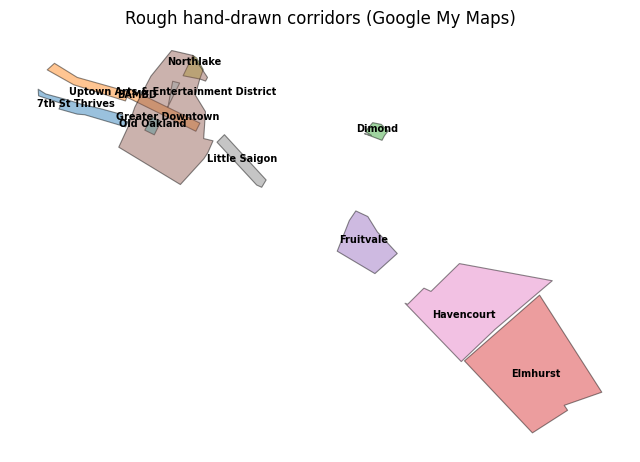

In [5]:
rows = []
for a, b in itertools.combinations(corridors.itertuples(), 2):
    inter = a.draw_geom.intersection(b.draw_geom).area
    if inter > 1:
        rows.append({"corridor_a": LABEL[a.corridor_id], "corridor_b": LABEL[b.corridor_id], "overlap_m2": inter,
                     "pct_of_a": 100 * inter / a.draw_area_m2, "pct_of_b": 100 * inter / b.draw_area_m2})
drawing_overlaps = pd.DataFrame(rows).sort_values("overlap_m2", ascending=False)
n_drawing_overlap_pairs = len(drawing_overlaps)
print(f"{n_drawing_overlap_pairs} overlapping drawing pairs (of {len(corridors)*(len(corridors)-1)//2} possible)")
display(drawing_overlaps)

fig, ax = plt.subplots(figsize=(8, 9))
corridors.plot(ax=ax, column="corridor_id", cmap="tab20", alpha=0.45, edgecolor="k", linewidth=0.8)
for r in corridors.itertuples():
    p = r.geometry.representative_point()
    ax.annotate(LABEL[r.corridor_id], (p.x, p.y), fontsize=7, ha="center", weight="bold")
ax.set_title("Rough hand-drawn corridors (Google My Maps)"); ax.set_aspect("equal"); ax.axis("off")
plt.show()

**Takeaways -- drawings**

* All **11** drawings are single, valid **Polygon** features (Google exports them as `Polygon Z`; Z is dropped). No lines and no multipart features, so no line-buffering special case is needed (`LINE_BUFFER_M` is unused). BAMBD has one interior hole.\n* **Hegenberger is not in this file**, so no corridor needed line-specific treatment.\n* The drawings span two orders of magnitude: Uptown (0.05 km2) to Elmhurst (4.8 km2). **Havencourt, Elmhurst and Greater Downtown (3.6-4.8 km2) are district-sized polygons, not street corridors**; the other eight look like conventional corridors.\n* Only **4 overlapping pairs**, all with Greater Downtown (Old Oakland and Uptown lie 100% inside it, Northlake 92%, BAMBD 41%). These overlaps are intentional and preserved.\n* The source name `'Dimond\\xa0'` carries a trailing non-breaking space. It is kept verbatim in `corridor_name` (the ID `c2_dimond` is slugified; display labels are stripped). You may want to clean this upstream.

# Section 2 -- A Reusable Oakland-Only Parcel Subset

**Question:** can we avoid touching the ~900 MB county parcel file again and again?

**Approach:** the county shapefile (EPSG:3857) is read **once**, with the Oakland boundary passed as a spatial
`mask` so only features intersecting Oakland are ever loaded, and only the identifier / address /
use-code / value columns are kept. The result is saved as `data/geo/parcels_subset/oakland_parcels.gpkg`
(native CRS, **not** dissolved) and reused on later runs. Invalid geometries are repaired only where needed.
A cheap `read_info` call gives the county feature count without loading geometry.

In [6]:
county_info = pyogrio.read_info(PARCELS_SHP)
n_county_parcels = int(county_info["features"])
print(f"Alameda County parcel features (from file metadata, nothing loaded): {n_county_parcels:,}")
print("Existing Oakland-only parcel files:", sorted(p.name for p in PARCEL_SUBSET_DIR.glob("*oakland*")) or "none")

def polygonal_only(geom):
    """make_valid can return a GeometryCollection; keep only its polygonal content."""
    if geom.geom_type in ("Polygon", "MultiPolygon"):
        return geom
    polys = [g for g in shapely.get_parts(geom) if g.geom_type in ("Polygon", "MultiPolygon")]
    return shapely.union_all(polys) if polys else geom

if OAKLAND_PARCELS_GPKG.exists():
    oak_action = "reused existing file"
    parcels_native = gpd.read_file(OAKLAND_PARCELS_GPKG, layer=OAKLAND_PARCELS_LAYER)
    n_invalid_fixed = int((~parcels_native.is_valid).sum())
else:
    oak_action = "created from county shapefile (mask read)"
    boundary = gpd.read_file(OAKLAND_BOUNDARY_GPKG).to_crs(county_info["crs"])
    parcels_native = gpd.read_file(PARCELS_SHP, mask=boundary.geometry.union_all(),
                                   columns=OAKLAND_PARCEL_COLUMNS, engine="pyogrio")
    invalid = ~parcels_native.is_valid
    n_invalid_fixed = int(invalid.sum())
    if n_invalid_fixed:
        fixed = shapely.make_valid(parcels_native.geometry.values[invalid.values])
        parcels_native.loc[invalid, "geometry"] = [polygonal_only(g) for g in fixed]
    parcels_native["UseCode_str"] = parcels_native[USE_CODE_FIELD]
    parcels_native.to_file(OAKLAND_PARCELS_GPKG, layer=OAKLAND_PARCELS_LAYER, driver="GPKG")
    del boundary

print(f"Oakland parcel subset: {oak_action}")
print(f"  rows: {len(parcels_native):,} | invalid geometries repaired: {n_invalid_fixed} | "
      f"file: {OAKLAND_PARCELS_GPKG.relative_to(ROOT)} ({OAKLAND_PARCELS_GPKG.stat().st_size/1e6:.1f} MB)")
print(f"  native CRS: {parcels_native.crs} | geometry types: {parcels_native.geom_type.value_counts().to_dict()}")
print(f"  valid after fix: {bool(parcels_native.is_valid.all())}")

# Working copy in the metric CRS; positional index == row label from here on
parcels = parcels_native.to_crs(CRS_METRIC).reset_index(drop=True)
del parcels_native
n_null_apn = int(parcels[PARCEL_ID_FIELD].isna().sum())
parcels[PARCEL_ID_FIELD] = parcels[PARCEL_ID_FIELD].fillna(pd.Series([f"NOAPN_{i}" for i in range(len(parcels))]))
parcels["area_m2"] = parcels.area
parcels["apn_area_m2"] = parcels.groupby(PARCEL_ID_FIELD).area_m2.transform("sum")   # all pieces of an APN
parcels_geoms = parcels.geometry.values
print(f"  null APNs replaced with placeholders: {n_null_apn}")

Alameda County parcel features (from file metadata, nothing loaded): 489,576
Existing Oakland-only parcel files: none


Oakland parcel subset: created from county shapefile (mask read)
  rows: 113,809 | invalid geometries repaired: 21 | file: data/geo/parcels_subset/oakland_parcels.gpkg (63.2 MB)
  native CRS: EPSG:3857 | geometry types: {'Polygon': 113656, 'MultiPolygon': 153}
  valid after fix: True


  null APNs replaced with placeholders: 0


Note that this subset is "parcels *intersecting* Oakland's boundary", so a few hundred parcels whose situs city is
a neighbour (Piedmont, Berkeley, Emeryville, San Leandro) are included along the edge. They are harmless for the
corridors here but are counted in the totals.

# Section 3 -- Understanding the Parcel Data and the Existing Subsets

**Question:** what is the parcel ID, how are use codes stored, are there duplicates, and what do the three
pre-built subsets in `data/geo/parcels_subset/` actually contain?

**Why it matters:** the commercial candidates lean on those subsets, and duplicate APNs / stacked
footprints (condominium units) affect how parcel counts and overlap ratios should be computed.

In [7]:
dup_apn_rows = int(parcels[PARCEL_ID_FIELD].duplicated(keep=False).sum())
dup_apn_ids = int(parcels.loc[parcels[PARCEL_ID_FIELD].duplicated(keep=False), PARCEL_ID_FIELD].nunique())
wkb = parcels.geometry.to_wkb()
stacked_rows = int(wkb.duplicated(keep=False).sum())
print(f"Oakland parcel rows: {len(parcels):,} | unique APNs: {parcels[PARCEL_ID_FIELD].nunique():,}")
print(f"Rows sharing an APN with another row: {dup_apn_rows} ({dup_apn_ids} APNs) -> multi-piece parcels, identical attributes, different geometry")
print(f"Rows whose footprint is IDENTICAL to another row's (stacked condo-type records): {stacked_rows:,} "
      f"({stacked_rows/len(parcels):.1%}) -> different APNs, same polygon")
print("Situs city of subset rows:", parcels.SitusCity.value_counts().head(6).to_dict())
print("Parcel area (m2) percentiles:", parcels.area_m2.quantile([.05, .25, .5, .75, .95, .999]).round(0).to_dict())
print("Use code stored as:", parcels[USE_CODE_FIELD].dtype, "| missing:", int(parcels[USE_CODE_FIELD].isna().sum()))
print("Example use codes:", parcels[USE_CODE_FIELD].dropna().sample(8, random_state=1).tolist())

Oakland parcel rows: 113,809 | unique APNs: 113,557
Rows sharing an APN with another row: 398 (146 APNs) -> multi-piece parcels, identical attributes, different geometry
Rows whose footprint is IDENTICAL to another row's (stacked condo-type records): 15,648 (13.7%) -> different APNs, same polygon
Situs city of subset rows: {'OAKLAND': 112905, 'BERKELEY': 259, 'PIEDMONT': 177, 'SAN LEANDRO': 162, 'EMERYVILLE': 158, 'CASTRO VALLEY': 27}
Parcel area (m2) percentiles: {0.05: 225.0, 0.25: 369.0, 0.5: 483.0, 0.75: 801.0, 0.95: 3989.0, 0.999: 108912.0}
Use code stored as: object | missing: 101
Example use codes: ['4100', '1100', '1100', '1000', '3200', '1100', '1100', '2100']


**Handling of duplicates.** Overlap ratios are computed **per APN** (summing the pieces), and parcels are counted per
unique APN. Stacked identical footprints are harmless to the dissolve (they union to one polygon), but they inflate
raw parcel counts, so counts below are always *unique APNs* and areas are always areas of the *union*.

### The three pre-built subsets

In [8]:
def read_apn_codes(path):
    layer = pyogrio.list_layers(path)[0][0]
    return pyogrio.read_dataframe(path, layer=layer, columns=[PARCEL_ID_FIELD, "UseCode_str"], read_geometry=False)

subsets = {p.stem: read_apn_codes(p) for p in sorted(PARCEL_SUBSET_DIR.glob("parcels_*.gpkg"))}
oak_apns = set(parcels[PARCEL_ID_FIELD])
use_apns = set(subsets["parcels_use_code_filtered"][PARCEL_ID_FIELD])
biz_apns = set(subsets["parcels_with_business"][PARCEL_ID_FIELD])
union_apns = set(subsets["parcels_union"][PARCEL_ID_FIELD])

rows = []
for name, df in subsets.items():
    lead = df.UseCode_str.astype("string").str[0]
    rows.append({"subset": name, "layers": pyogrio.list_layers(PARCEL_SUBSET_DIR / f"{name}.gpkg")[:, 0].tolist(),
                 "rows": len(df), "unique_APN": df[PARCEL_ID_FIELD].nunique(),
                 "apn_in_oakland_parcels": df[PARCEL_ID_FIELD].isin(oak_apns).mean(),
                 "pct_use_3_8_9": lead.isin(list(COMMERCIAL_USE_CODE_PREFIXES)).mean(),
                 "pct_use_1_2_residential": lead.isin(["1", "2"]).mean()})
display(pd.DataFrame(rows))

print("union == use_code U business :", union_apns == (use_apns | biz_apns))
print(f"APNs in both: {len(use_apns & biz_apns):,} | use-code only: {len(use_apns - biz_apns):,} | business only: {len(biz_apns - use_apns):,}")
oak_lead = parcels[USE_CODE_FIELD].astype("string").str[0]
oak_use_rule = set(parcels.loc[oak_lead.isin(list(COMMERCIAL_USE_CODE_PREFIXES)), PARCEL_ID_FIELD])
print(f"Oakland parcels with use code 3/8/9: {len(oak_use_rule):,} unique APNs -> in use-code subset: {len(oak_use_rule & use_apns)/len(oak_use_rule):.1%}")
print("\nTop use codes among business-only parcels (have a business, but NOT a 3/8/9 use code):")
display(subsets["parcels_with_business"][~subsets["parcels_with_business"][PARCEL_ID_FIELD].isin(use_apns)]
        .drop_duplicates(PARCEL_ID_FIELD).UseCode_str.value_counts().head(8).rename("n_parcels").to_frame())

,subset,layers,rows,unique_APN,apn_in_oakland_parcels,pct_use_3_8_9,pct_use_1_2_residential
0,parcels_union,[parcels_union],18365,18272,1.000,0.291,0.148
1,parcels_use_code_filtered,[parcels_use_code_filtered],5346,5343,1.000,1.000,0.000
2,parcels_with_business,[parcels_with_business],15855,15765,1.000,0.179,0.172


union == use_code U business : True
APNs in both: 2,836 | use-code only: 2,507 | business only: 12,929
Oakland parcels with use code 3/8/9: 5,374 unique APNs -> in use-code subset: 99.4%

Top use codes among business-only parcels (have a business, but NOT a 3/8/9 use code):


,n_parcels
UseCode_str,
7300,6534
1100,1907
7305,532
7301,474
7700,447
4100,372
0300,275
6600,244


**What each subset represents** (inferred from the data, not from filenames):

* `parcels_use_code_filtered` -- parcels whose `UseCode` starts with 3, 8 or 9 (the use-code definition of "business-oriented"). Every such Oakland parcel is present.
* `parcels_with_business` -- parcels that contain at least one business from the business dataset, **regardless of use code** (so it includes residential parcels with home-based businesses, and many 7xxx records).
* `parcels_union` -- the exact union of the two above. This is the layer used for the `COMMERCIAL` candidates.

These files are used only for **APN membership** (flags). Geometries always come from the Oakland parcel subset,
which is deduplicated per APN and validity-repaired. Three flags are attached to every Oakland parcel row.

In [9]:
parcels["flag_use_code"] = parcels[PARCEL_ID_FIELD].isin(use_apns)
parcels["flag_business"] = parcels[PARCEL_ID_FIELD].isin(biz_apns)
parcels["flag_commercial"] = parcels[PARCEL_ID_FIELD].isin(union_apns)
parcels["commercial_basis"] = np.select(
    [parcels.flag_use_code & parcels.flag_business, parcels.flag_use_code, parcels.flag_business],
    ["use_code+business", "use_code", "business"], default="none")
print(parcels.drop_duplicates(PARCEL_ID_FIELD).commercial_basis.value_counts().to_dict())
print("Unique commercial/business APNs found in Oakland parcels:",
      parcels.loc[parcels.flag_commercial, PARCEL_ID_FIELD].nunique(), "of", len(union_apns))

{'none': 95285, 'business': 12929, 'use_code+business': 2836, 'use_code': 2507}
Unique commercial/business APNs found in Oakland parcels: 18272 of 18272


**Takeaways -- parcels**

* **489,576** county parcels were never loaded in full: the mask read pulled **113,809** Oakland-intersecting rows (113,557 unique APNs) in seconds. 21 invalid geometries were repaired; the subset is saved once as `oakland_parcels.gpkg` and reused thereafter.\n* 146 APNs are **multi-piece parcels** (same attributes, several polygons) and **13.7% of rows are stacked identical footprints** (different APNs, same polygon, typically condo-style records). Ratios are therefore computed per APN and areas are always areas of the union; raw parcel counts overstate physical parcels, especially downtown.\n* `parcels_union` is *exactly* `parcels_use_code_filtered` + `parcels_with_business` (2,836 in both, 2,507 use-code only, 12,929 business only). Business-only parcels are mostly 7300/7305/7301 records, plus **1,907 single-family (1100) parcels** with a business, so `COMMERCIAL` includes some home-based-business residential lots (about 15% of the union has a 1xxx/2xxx use code). Inspect that in QGIS using `commercial_basis` / `use_code` in the selected-parcels file.

# Section 4 -- How Wide Are Oakland's Street Gaps?

**Question:** what closing distance is appropriate for bridging the street space between parcels?

**Approach:** for every Oakland parcel, measure the distance to its nearest *non-touching* neighbour. Across a
block face, neighbouring parcels touch (distance ~0); the nearest non-touching neighbour is typically the parcel
across a street or alley. The distribution therefore reveals the physical width of the gaps we need to fill.

A morphological closing with radius *r* (buffer out by *r*, then back in by *r*) bridges gaps up to about **2r**.

count   113,764.000
mean          9.000
std           5.400
min           0.300
10%           2.300
25%           4.700
50%           8.800
75%          12.200
90%          15.200
95%          18.300
99%          24.400
max          79.800


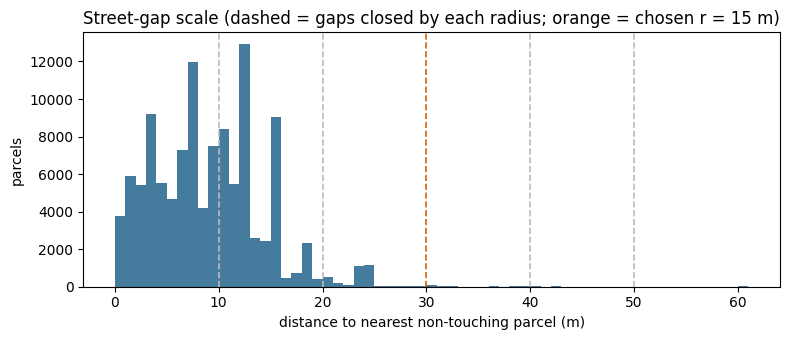

Share of parcels whose nearest non-touching neighbour is within 30 m: 99.7%


In [10]:
nn_dist = np.full(len(parcels), np.nan)
q_i, q_j = shapely.STRtree(parcels_geoms).query(parcels_geoms, predicate="dwithin", distance=NEIGHBOUR_SEARCH_M)
keep = q_i != q_j
q_i, q_j = q_i[keep], q_j[keep]
d = shapely.distance(parcels_geoms[q_i], parcels_geoms[q_j])
pair = pd.DataFrame({"i": q_i, "d": d})
pair = pair[pair.d > 0.3]                       # drop touching neighbours
nn = pair.groupby("i").d.min()
nn_dist[nn.index.values] = nn.values
parcels["nn_gap_m"] = nn_dist

print(nn.describe(percentiles=[.1, .25, .5, .75, .9, .95, .99]).round(1).to_string())
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(nn.clip(upper=60), bins=np.arange(0, 62, 1), color="#457b9d")
for r in CLOSE_DIST_SWEEP_M:
    ax.axvline(2 * r, color="#d95f02" if r == CLOSE_DIST_M else "#bbb", ls="--", lw=1.2)
ax.set(xlabel="distance to nearest non-touching parcel (m)", ylabel="parcels",
       title=f"Street-gap scale (dashed = gaps closed by each radius; orange = chosen r = {CLOSE_DIST_M:g} m)")
plt.tight_layout(); plt.show()
share = (nn <= 2 * CLOSE_DIST_M).mean()
print(f"Share of parcels whose nearest non-touching neighbour is within {2*CLOSE_DIST_M:g} m: {share:.1%}")

**Takeaways -- scale**

* The typical Oakland street gap is small: **median 8.8 m, 90% under 15.2 m, 99% under 24.4 m**. Alleys, side streets and arterials all fall below 30 m.\n* `CLOSE_DIST_M = 15` (bridges gaps up to 30 m) therefore covers **99.7%** of parcels' nearest cross-street neighbours without needing anything larger. Larger radii would mostly add area, not connectivity (see Section 6 sweep).

# Section 5 -- Selecting Parcels for Each Corridor

**Question:** which Oakland parcels belong to each rough drawing?

**Rule (denominator is the *parcel*):**

    parcel_overlap_ratio = area(parcel ∩ drawing) / area(parcel)         (summed over pieces of the same APN)

A parcel is selected when the ratio is at least `PARCEL_OVERLAP_THRESHOLD = 2/3`. A parcel that merely touches a
drawing, or is mostly outside it, is not selected, regardless of how much of the *drawing* it covers.
Polygons are used exactly as drawn; no buffering is applied to them.

The loop runs corridor-by-corridor against a spatial index, so only parcels near each drawing are touched.

In [11]:
tree_parcels = shapely.STRtree(parcels_geoms)
cand_frames = []
for c in tqdm(list(corridors.itertuples()), desc="Overlap ratios per corridor"):
    pos = tree_parcels.query(c.draw_geom, predicate="intersects")
    ia = shapely.area(shapely.intersection(parcels_geoms[pos], c.draw_geom))
    f = pd.DataFrame({"corridor_id": c.corridor_id, "pos": pos, "ia": ia})
    f["APN"] = parcels[PARCEL_ID_FIELD].values[pos]
    f["apn_area"] = parcels.apn_area_m2.values[pos]
    f["ratio"] = f.groupby("APN").ia.transform("sum") / f.apn_area
    cand_frames.append(f)
cand = pd.concat(cand_frames, ignore_index=True)
cand["commercial"] = parcels.flag_commercial.values[cand.pos]
cand["use_code"] = parcels.UseCode_str.values[cand.pos]
cand = cand[cand.ratio > 0]                          # drop zero-area (touching-only) intersections
cand["ratio"] = cand.ratio.clip(upper=1.0)
print(f"{len(cand):,} parcel rows intersect at least one drawing")

Overlap ratios per corridor:   0%|          | 0/11 [00:00<?, ?it/s]

21,355 parcel rows intersect at least one drawing


In [12]:
capn = cand.drop_duplicates(["corridor_id", "APN"])
rows = []
for cid, g in capn.groupby("corridor_id", sort=False):
    row = {"corridor": LABEL[cid], "intersecting_APN": len(g),
           f"ratio>={PARCEL_OVERLAP_THRESHOLD:.2f} (MAXIMAL)": int((g.ratio >= PARCEL_OVERLAP_THRESHOLD).sum()),
           "near_miss (0.5-0.67)": int(((g.ratio >= NEAR_MISS_MIN_RATIO) & (g.ratio < PARCEL_OVERLAP_THRESHOLD)).sum()),
           "commercial_intersecting": int(g.commercial.sum()),
           "commercial_selected (COMMERCIAL)": int((g.commercial & (g.ratio >= COMMERCIAL_OVERLAP_THRESHOLD)).sum()),
           "commercial_near_miss": int((g.commercial & (g.ratio >= NEAR_MISS_MIN_RATIO) & (g.ratio < COMMERCIAL_OVERLAP_THRESHOLD)).sum())}
    rows.append(row)
selection_table = pd.DataFrame(rows).set_index("corridor")
display(selection_table.astype(int))

print("Commercial/business parcels retained as the overlap threshold varies (unique APNs):")
sens = pd.DataFrame({f">={t:.2f}": capn[capn.commercial & (capn.ratio >= t)].groupby("corridor_id").size()
                     for t in OVERLAP_SENSITIVITY_THRESHOLDS}).fillna(0).astype(int)
sens.index = [LABEL[i] for i in sens.index]
display(sens)

,intersecting_APN,ratio>=0.67 (MAXIMAL),near_miss (0.5-0.67),commercial_intersecting,commercial_selected (COMMERCIAL),commercial_near_miss
corridor,,,,,,
Old Oakland,105,105,0,84,84,0
Little Saigon,464,377,1,148,140,0
Fruitvale,1305,1265,15,310,290,8
Dimond,136,111,5,61,55,1
Havencourt,4680,4585,21,329,301,5
Elmhurst,6159,6036,15,490,480,0
Uptown Arts & Entertainment District,73,72,0,70,69,0
Northlake,354,354,0,74,74,0
BAMBD,1189,980,23,515,372,10


Commercial/business parcels retained as the overlap threshold varies (unique APNs):


,>=0.01,>=0.25,>=0.50,>=0.67,>=0.80,>=0.90
7th St Thrives,94,91,90,90,88,86
BAMBD,515,414,382,372,320,152
Dimond,61,57,56,55,55,54
Elmhurst,490,489,480,480,478,472
Fruitvale,309,301,298,290,275,274
Greater Downtown,5023,5011,4918,4914,4910,4908
Havencourt,328,317,306,301,295,293
Little Saigon,148,140,140,140,140,140
Northlake,74,74,74,74,74,74
Old Oakland,84,84,84,84,84,84


**Takeaways -- selection**

* Few parcels narrowly miss the 2/3 rule: **99** near-miss parcels across all drawings for `MAXIMAL` and **28** commercial near-misses (concentrated in BAMBD, Fruitvale and Havencourt). They are not auto-included.\n* Applying the 2/3 rule to commercial/business parcels removes only about **4.6%** of the 7,201 commercial parcels that touch any drawing (6,869 retained). Elmhurst, Northlake, Old Oakland, Uptown and Little Saigon are nearly insensitive to the threshold. **BAMBD is the exception** (372 at 2/3, 320 at 0.8, only 152 at 0.9) because its drawing cuts across commercial parcels that front the corridor, so its commercial set depends on the threshold choice.\n* Commercial share differs hugely between drawings: Greater Downtown, Uptown and Old Oakland are ~80-96% commercial/business parcels, whereas Havencourt (329 of 4,680 intersecting parcels) and Elmhurst (490 of 6,159) are overwhelmingly residential.

# Section 6 -- Making a Selected Parcel Set Continuous

**Problem.** Dissolving selected parcels leaves street gaps, so the result is a cluster of block-sized islands.

**Method (conservative, reproducible, 4 steps, all parameters in the constants cell):**

1. **Dissolve** the selected parcels (`n_parts_before_gap_fill` is the number of parts here).
2. **Close street gaps.** Morphological closing with radius `CLOSE_DIST_M`
   (buffer out -> union -> buffer back in). Only the *added* material (closing minus original parcels) is kept,
   and it is **clipped to a `DRAWING_MAX_BUFFER_M` buffer of the source drawing**, so the corridor can overspill the
   sketch slightly but can never creep into neighbouring districts. The parcels themselves are never clipped.
3. **Fill holes.** Interior holes under `HOLE_MAX_AREA_M2` are always filled (slivers, courtyards); holes up to
   `HOLE_MAX_AREA_IN_DRAWING_M2` are filled only if >= 90% inside the drawing. Large holes (genuine unselected blocks) stay.
4. **Drop small disconnected fragments** below `MIN_FRAGMENT_AREA_M2` (the largest part is always kept), then apply a
   light `SIMPLIFY_TOL_M` simplification to reduce parcel-corner vertices. Parcels inside dropped fragments are removed
   from the selected set, so the final polygon stays reproducible from the selected parcels.

Closing with radius *r* bridges gaps up to 2*r*. For the candidate stage a single radius of 15 m is used (it covers 99.7% of
nearest street gaps, Section 4). The *final* stage replaces this one-size-fits-all choice with corridor-specific settings (Sections 10-12).

In [13]:
def polys_of(geom):
    if geom is None or geom.is_empty:
        return []
    return [g for g in shapely.get_parts(geom) if g.geom_type == "Polygon"]

def n_parts(geom):
    return len(polys_of(geom))

def close_gaps(union_geom, draw, close_m=CLOSE_DIST_M):
    closed = union_geom.buffer(close_m, quad_segs=BUFFER_QUAD_SEGS).buffer(-close_m, quad_segs=BUFFER_QUAD_SEGS)
    allowed = draw.buffer(DRAWING_MAX_BUFFER_M, quad_segs=BUFFER_QUAD_SEGS)
    extension = closed.difference(union_geom).intersection(allowed)
    return union_geom.union(extension)

def fill_small_holes(geom, draw):
    out = []
    for poly in polys_of(geom):
        keep = []
        for ring in poly.interiors:
            hole = Polygon(ring)
            a = hole.area
            if a < HOLE_MAX_AREA_M2:
                continue
            if a < HOLE_MAX_AREA_IN_DRAWING_M2 and hole.intersection(draw).area / a >= HOLE_MIN_FRACTION_IN_DRAWING:
                continue
            keep.append(ring)
        out.append(Polygon(poly.exterior, keep))
    return shapely.union_all(out)

def drop_small_fragments(geom, min_area=MIN_FRAGMENT_AREA_M2):
    parts = sorted(polys_of(geom), key=lambda g: -g.area)
    kept = [g for i, g in enumerate(parts) if i == 0 or g.area >= min_area]
    dropped = [g for i, g in enumerate(parts) if i > 0 and g.area < min_area]
    return shapely.union_all(kept), (shapely.union_all(dropped) if dropped else Polygon())

def build_corridor_geometry(parcel_geoms, draw):
    """dissolve -> close street gaps (bounded by drawing buffer) -> fill holes -> drop fragments -> simplify."""
    dissolved = shapely.union_all(parcel_geoms)
    closed = close_gaps(dissolved, draw)
    filled = fill_small_holes(closed, draw)
    kept, dropped = drop_small_fragments(filled)
    final = shapely.make_valid(kept.simplify(SIMPLIFY_TOL_M, preserve_topology=True))
    return {"dissolved": dissolved, "filled": filled, "kept": kept, "dropped": dropped, "final": final}

**Takeaways -- gap filling**

* The candidate stage uses one radius (**15 m**, justified by the Section 4 gap distribution) so that all 33 candidates are comparable. That already collapses most MAXIMAL corridors to 1-5 parts, but it leaves several corridors split by gaps just over 30 m (see Section 11) and the COMMERCIAL-based versions stay fragmented.\n* The final stage therefore uses **corridor-specific** radii instead of enlarging this global value.\n* About 14-29% of the final MAXIMAL area is street/gap fill, which is expected: parcel polygons exclude the right-of-way.

# Section 7 -- Building the Candidate Corridors

For each corridor and each method the loop does: *select parcels -> dissolve -> gap-fill -> record diagnostics*.
Every corridor is processed independently. **No overlaps are removed and nothing is partitioned.**

* **MAXIMAL** -- every parcel with ratio >= `PARCEL_OVERLAP_THRESHOLD`.
* **COMMERCIAL** -- the subset of those that are in `parcels_union` (use code 3/8/9 or contains a business), ratio >= `COMMERCIAL_OVERLAP_THRESHOLD`.
* **COMMERCIAL_COMPLETED** -- `COMMERCIAL` plus non-commercial parcels from the MAXIMAL set that are >= `COMPLETION_OVERLAP_THRESHOLD` inside the drawing **and** either
  (a) touch (within `ADJACENCY_TOL_M`) at least `COMPLETION_MIN_COMMERCIAL_NEIGHBOURS` distinct commercial parcels (infill lots on the frontage), or
  (b) lie inside the already gap-filled `COMMERCIAL` envelope (enclosed pockets). It is a single pass -- no iterative growth -- so it cannot creep outward block by block.

In [14]:
def select_rows(ca, method):
    if method == METHOD_MAXIMAL:
        r = ca[ca.ratio >= PARCEL_OVERLAP_THRESHOLD].copy()
        r["selection_reason"] = "overlap"
    else:
        r = ca[(ca.ratio >= COMMERCIAL_OVERLAP_THRESHOLD) & ca.commercial].copy()
        r["selection_reason"] = "commercial_overlap"
    return r

def completion_rows(ca, base_rows, base_filled):
    """Non-commercial MAXIMAL parcels that are strongly inside the drawing and sandwiched by / enclosed in the commercial set."""
    pool = ca[(ca.ratio >= max(PARCEL_OVERLAP_THRESHOLD, COMPLETION_OVERLAP_THRESHOLD)) & ~ca.commercial]
    pool = pool[~pool.APN.isin(base_rows.APN)]
    if pool.empty:
        return pool.assign(selection_reason=pd.Series(dtype=str))
    pool_geoms = parcels_geoms[pool.pos.values]
    base_geoms = parcels_geoms[base_rows.pos.values]
    pi, bi = shapely.STRtree(base_geoms).query(pool_geoms, predicate="dwithin", distance=ADJACENCY_TOL_M)
    nbrs = pd.DataFrame({"pool_i": pi, "base_apn": base_rows.APN.values[bi]}).drop_duplicates()
    n_nbr = nbrs.groupby("pool_i").size().reindex(range(len(pool)), fill_value=0).values
    adjacent = n_nbr >= COMPLETION_MIN_COMMERCIAL_NEIGHBOURS
    enclosed = shapely.contains(base_filled, shapely.point_on_surface(pool_geoms))
    pool = pool.assign(selection_reason=np.select([adjacent, enclosed], ["completion_infill", "completion_enclosed"], default=""))
    return pool[pool.selection_reason != ""]

def build_candidate(rows, draw):
    geoms = parcels_geoms[rows.pos.values]
    res = build_corridor_geometry(geoms, draw)
    keep = shapely.intersects(geoms, res["kept"])
    res["n_dropped_rows"] = int((~keep).sum())
    return res, rows[keep]

def candidate_record(cid, method, res, rows_kept, rows_all):
    draw = DRAW[cid]
    final = res["final"]
    pu = shapely.union_all(parcels_geoms[rows_kept.pos.values])
    unique = rows_kept.drop_duplicates("APN")
    in_draw = final.intersection(draw).area
    ext_area = final.difference(pu).area
    parts = sorted([g.area for g in polys_of(final)], reverse=True)
    return {
        "corridor_id": cid, "corridor_name": NAME[cid], "method": method,
        "n_selected_parcels": len(unique),
        "n_business_relevant_parcels": int(unique.commercial.sum()),
        "n_non_business_parcels": int((~unique.commercial).sum()),
        "n_dropped_parcels_in_fragments": int(rows_all.APN.nunique() - len(unique)),
        "selected_parcel_area": pu.area,
        "final_polygon_area": final.area,
        "pct_gap_fill_area": 100 * ext_area / final.area,
        "pct_final_area_within_original_drawing": 100 * in_draw / final.area,
        "pct_original_drawing_covered": 100 * in_draw / draw.area,
        "n_parts_before_gap_fill": n_parts(res["dissolved"]),
        "n_parts_after_gap_fill": len(parts),
        "pct_area_in_largest_part": 100 * parts[0] / final.area,
        "n_fragments_dropped": n_parts(res["dropped"]),
        "n_vertices": int(shapely.get_num_coordinates(final)),
    }

results, store, sel_frames = [], {}, []
for c in tqdm(list(corridors.itertuples()), desc="Corridors"):
    cid = c.corridor_id
    ca = cand[cand.corridor_id == cid]
    draw = DRAW[cid]
    # MAXIMAL
    rows_a = select_rows(ca, METHOD_MAXIMAL)
    res_a, kept_a = build_candidate(rows_a, draw)
    # COMMERCIAL
    rows_b = select_rows(ca, METHOD_COMMERCIAL)
    res_b, kept_b = build_candidate(rows_b, draw)
    # COMMERCIAL_COMPLETED (starts from all COMMERCIAL rows so additions can rescue small fragments)
    extra = completion_rows(ca, rows_b, res_b["filled"])
    rows_c = pd.concat([rows_b, extra])
    res_c, kept_c = build_candidate(rows_c, draw)
    for method, res, kept, allr in [(METHOD_MAXIMAL, res_a, kept_a, rows_a), (METHOD_COMMERCIAL, res_b, kept_b, rows_b),
                                    (METHOD_COMPLETED, res_c, kept_c, rows_c)]:
        results.append(candidate_record(cid, method, res, kept, allr))
        store[(cid, method)] = {**res, "rows": kept}
        sel_frames.append(kept.assign(method=method))

summary = pd.DataFrame(results)
selected_rows = pd.concat(sel_frames, ignore_index=True)
print("Built", len(summary), "corridor x method candidates")

Corridors:   0%|          | 0/11 [00:00<?, ?it/s]

Built 33 corridor x method candidates


### Summary table: one row per corridor x method

In [15]:
summary["_o"] = summary.corridor_id.map({cid: i for i, cid in enumerate(corridors.corridor_id)})
summary["_m"] = summary.method.map({m: i for i, m in enumerate(METHODS)})
summary = summary.sort_values(["_o", "_m"]).drop(columns=["_o", "_m"]).reset_index(drop=True)
view = summary.drop(columns=["corridor_id"]).copy()
view["corridor_name"] = view.corridor_name.str.strip()
view["selected_parcel_area"] /= 1e4; view["final_polygon_area"] /= 1e4
view = view.rename(columns={"selected_parcel_area": "sel_parcel_area_ha", "final_polygon_area": "final_area_ha",
                            "pct_final_area_within_original_drawing": "pct_final_in_drawing",
                            "pct_original_drawing_covered": "pct_drawing_covered",
                            "n_parts_before_gap_fill": "parts_before", "n_parts_after_gap_fill": "parts_after",
                            "n_business_relevant_parcels": "n_business", "n_non_business_parcels": "n_non_business",
                            "n_dropped_parcels_in_fragments": "n_dropped", "pct_area_in_largest_part": "pct_in_largest_part",
                            "n_fragments_dropped": "frags_dropped", "n_selected_parcels": "n_parcels"})
display(view.round(1))

,corridor_name,method,n_parcels,n_business,n_non_business,n_dropped,sel_parcel_area_ha,final_area_ha,pct_gap_fill_area,pct_final_in_drawing,pct_drawing_covered,parts_before,parts_after,pct_in_largest_part,frags_dropped,n_vertices
0,Old Oakland,MAXIMAL,105,84,21,0,4.700,6.500,28.100,100.000,78.900,7,1,100.000,0,39
1,Old Oakland,COMMERCIAL,84,84,0,0,3.600,5.100,28.900,100.000,62.100,7,1,100.000,0,54
2,Old Oakland,COMMERCIAL_COMPLETED,103,84,19,0,3.800,5.300,28.600,100.000,64.200,7,1,100.000,0,45
3,Little Saigon,MAXIMAL,377,140,237,0,20.600,27.800,26.200,99.900,83.100,29,1,100.000,1,184
4,Little Saigon,COMMERCIAL,137,137,0,3,9.500,14.900,36.400,100.000,44.400,49,2,90.500,3,351
5,Little Saigon,COMMERCIAL_COMPLETED,225,140,85,0,13.800,19.100,27.400,100.000,56.900,29,2,86.500,0,256
6,Fruitvale,MAXIMAL,1262,289,973,3,70.400,90.100,21.900,99.400,87.500,64,3,75.400,2,329
7,Fruitvale,COMMERCIAL,262,262,0,28,22.700,28.200,19.600,98.700,27.300,90,10,34.300,20,703
8,Fruitvale,COMMERCIAL_COMPLETED,387,266,121,32,28.700,33.700,14.800,98.900,32.600,75,8,33.200,17,636
9,Dimond,MAXIMAL,111,55,56,0,7.400,9.600,23.400,98.700,77.700,11,1,100.000,0,84


**Takeaways -- candidates**

* **MAXIMAL**: 20,403 parcel selections, 1,353 ha total; 6 of 11 corridors are single-part and at most 5 parts. BAMBD (5 parts, only 29% of area in the largest) is split where a long strip of non-selected parcels (a rail/freeway-type corridor visible on its map) crosses the drawing; Greater Downtown, Fruitvale and Elmhurst have 3-5 parts but 72-84% of area in one part.\n* **COMMERCIAL**: 6,532 selections, 452 ha; only 3 corridors are single-part and Havencourt (22 parts), Elmhurst (21), Fruitvale (10) and BAMBD (11) are strongly fragmented, with dozens to >150 isolated small commercial parcels dropped as fragments (Elmhurst 154 parcels, Havencourt 107, Fruitvale 28, BAMBD 17).\n* **COMMERCIAL_COMPLETED**: 8,296 selections, 548 ha; modestly more continuous (median 70% of area in the largest part vs 56% for COMMERCIAL).\n* In every candidate **>=96.8%** of final area lies inside the original drawing, and nothing extends beyond selected parcels plus the 25 m drawing buffer.

### How much do the methods differ?

For each corridor: parcels in `MAXIMAL` but not `COMMERCIAL`, area difference, the Jaccard overlap (IoU) of the
final polygons, parcels added by completion, and how fragmented `COMMERCIAL` was before and after filling.

In [16]:
rows = []
for cid in corridors.corridor_id:
    a, b, c = (store[(cid, m)] for m in METHODS)
    pa, pb, pc = (set(x["rows"].APN) for x in (a, b, c))
    fa, fb, fc = a["final"], b["final"], c["final"]
    rows.append({
        "corridor": LABEL[cid],
        "parcels_MAX_not_COMM": len(pa - pb), "parcels_COMM_not_MAX": len(pb - pa),
        "pct_MAX_parcels_commercial": 100 * len(pb & pa) / max(len(pa), 1),
        "area_MAX_ha": fa.area / 1e4, "area_COMM_ha": fb.area / 1e4, "COMM_as_pct_of_MAX_area": 100 * fb.area / fa.area,
        "IoU_MAX_vs_COMM": fa.intersection(fb).area / fa.union(fb).area,
        "COMM_in_MAX_pct": 100 * fb.intersection(fa).area / fb.area,
        "parcels_added_by_completion": len(pc - pb), "area_COMPLETED_ha": fc.area / 1e4,
        "COMM_parts_before_fill": n_parts(b["dissolved"]), "COMM_parts_after_fill": n_parts(fb),
    })
method_diff = pd.DataFrame(rows).set_index("corridor")
display(method_diff.round(2))

,parcels_MAX_not_COMM,parcels_COMM_not_MAX,pct_MAX_parcels_commercial,area_MAX_ha,area_COMM_ha,COMM_as_pct_of_MAX_area,IoU_MAX_vs_COMM,COMM_in_MAX_pct,parcels_added_by_completion,area_COMPLETED_ha,COMM_parts_before_fill,COMM_parts_after_fill
corridor,,,,,,,,,,,,
Old Oakland,21,0,80.000,6.490,5.110,78.690,0.790,100.000,19,5.280,7,1
Little Saigon,240,0,36.340,27.850,14.870,53.410,0.530,99.970,88,19.050,49,2
Fruitvale,1000,0,20.760,90.060,28.240,31.350,0.310,99.970,125,33.690,90,10
Dimond,57,0,48.650,9.610,6.500,67.650,0.680,99.960,14,7.150,12,1
Havencourt,4391,0,4.230,341.640,59.560,17.430,0.170,99.990,115,86.410,177,22
Elmhurst,5702,0,5.410,463.640,81.450,17.570,0.180,99.990,186,102.340,240,21
Uptown Arts & Entertainment District,3,0,95.830,3.050,2.630,86.140,0.860,100.000,2,2.930,5,1
Northlake,282,0,20.340,10.770,6.850,63.580,0.640,99.990,257,8.790,11,2
BAMBD,624,0,36.260,54.170,23.500,43.380,0.430,99.950,141,26.510,53,11


**Takeaways -- method differences**

* COMMERCIAL is a strict subset of MAXIMAL (>=99.9% of its area lies inside MAXIMAL). How much it narrows things depends on the drawing: Uptown, Old Oakland and Greater Downtown are **78-96% commercial** (COMMERCIAL keeps 67-86% of MAXIMAL area), whereas **Havencourt and Elmhurst are only ~4-5% commercial parcels (about 17-18% of MAXIMAL area)** and Fruitvale 31%.\n* So for the big residential-dominated drawings MAXIMAL is essentially the drawing itself, and COMMERCIAL is a different object: scattered commercial/institutional patches.\n* Completion adds 2-186 parcels for most corridors (Northlake +257 and Greater Downtown +775 parcel counts are inflated by stacked condo-style footprints; compare areas instead: those two grow by only +28% and +14% over COMMERCIAL).

# Section 8 -- Candidate Geometry Quality Control

Before export we verify: validity, polygonal type, no empties, preserved names, stable unique IDs, unexpected
multipart outputs, that gap filling never reached beyond (selected parcels ∪ drawing buffer), that corridors were
not merged with each other, and that **overlaps between different corridors were retained**.

In [17]:
final_gdf = gpd.GeoDataFrame(
    summary.assign(
        n_parcels=summary.n_selected_parcels,
        area_m2=summary.final_polygon_area,
    ), geometry=[store[(r.corridor_id, r.method)]["final"] for r in summary.itertuples()], crs=CRS_METRIC)

qc = {}
qc["all valid"] = bool(final_gdf.is_valid.all())
qc["no empties"] = bool((~final_gdf.is_empty).all())
qc["geom types"] = final_gdf.geom_type.value_counts().to_dict()
qc["unique (corridor_id, method)"] = not final_gdf.duplicated(["corridor_id", "method"]).any()
qc["names preserved verbatim"] = bool((final_gdf.drop_duplicates("corridor_id").set_index("corridor_id").corridor_name
                                       == corridors.set_index("corridor_id").corridor_name).all())
qc["n features"] = f"{len(final_gdf)} = {final_gdf.corridor_id.nunique()} corridors x {final_gdf.method.nunique()} methods"
# Gap filling must stay within (selected parcels U drawing-buffer); simplification tolerance allowed
leak = []
for r in final_gdf.itertuples():
    s = store[(r.corridor_id, r.method)]
    limit = shapely.union_all([shapely.union_all(parcels_geoms[s["rows"].pos.values]), DRAW[r.corridor_id].buffer(DRAWING_MAX_BUFFER_M)]).buffer(SIMPLIFY_TOL_M + 0.5)
    leak.append(r.geometry.difference(limit).area)
qc["max area outside (parcels U drawing buffer), m2"] = round(max(leak), 2)
display(pd.Series(qc, name="QC").to_frame())

# Overlaps between corridors: every pair of drawings that overlaps must still overlap in every method
ov_rows = []
for m in METHODS:
    g = final_gdf[final_gdf.method == m].set_index("corridor_id").geometry
    n_final = sum(g[a].intersection(g[b]).area > 1 for a, b in itertools.combinations(g.index, 2))
    ov_rows.append({"method": m, "overlapping_pairs": n_final, "overlapping_pairs_in_drawings": n_drawing_overlap_pairs,
                    "total_overlap_ha": sum(g[a].intersection(g[b]).area for a, b in itertools.combinations(g.index, 2)) / 1e4})
display(pd.DataFrame(ov_rows))

# Corridors needing attention
flags = summary.assign(
    multipart=summary.n_parts_after_gap_fill > 1,
    low_in_drawing=summary.pct_final_area_within_original_drawing < 90,
    fragments_dropped=summary.n_fragments_dropped > 0,
    mostly_fragmented=summary.pct_area_in_largest_part < 80)
flagged = flags[flags.multipart | flags.low_in_drawing | flags.mostly_fragmented | flags.fragments_dropped]
display(flagged[["corridor_id", "method", "n_parts_after_gap_fill", "pct_area_in_largest_part", "pct_final_area_within_original_drawing",
                 "n_fragments_dropped", "n_dropped_parcels_in_fragments"]].round(1))
print("Corridors with a leading/trailing space in the source name (kept verbatim):", [repr(n) for n in corridors.corridor_name if n != n.strip()])

,QC
all valid,True
no empties,True
geom types,"{'MultiPolygon': 20, 'Polygon': 13}"
"unique (corridor_id, method)",True
names preserved verbatim,True
n features,33 = 11 corridors x 3 methods
"max area outside (parcels U drawing buffer), m2",0.000


,method,overlapping_pairs,overlapping_pairs_in_drawings,total_overlap_ha
0,MAXIMAL,4,4,42.252
1,COMMERCIAL,4,4,29.526
2,COMMERCIAL_COMPLETED,4,4,33.374


,corridor_id,method,n_parts_after_gap_fill,pct_area_in_largest_part,pct_final_area_within_original_drawing,n_fragments_dropped,n_dropped_parcels_in_fragments
3,c2_little_saigon,MAXIMAL,1,100.000,99.900,1,0
4,c2_little_saigon,COMMERCIAL,2,90.500,100.000,3,3
5,c2_little_saigon,COMMERCIAL_COMPLETED,2,86.500,100.000,0,0
6,c2_fruitvale,MAXIMAL,3,75.400,99.400,2,3
7,c2_fruitvale,COMMERCIAL,10,34.300,98.700,20,28
8,c2_fruitvale,COMMERCIAL_COMPLETED,8,33.200,98.900,17,32
10,c2_dimond,COMMERCIAL,1,100.000,99.300,1,1
11,c2_dimond,COMMERCIAL_COMPLETED,1,100.000,99.300,1,1
13,c2_havencourt,COMMERCIAL,22,28.200,99.900,87,107
14,c2_havencourt,COMMERCIAL_COMPLETED,18,45.600,99.900,76,101


Corridors with a leading/trailing space in the source name (kept verbatim): ["'Dimond\\xa0'"]


**Takeaways -- QC**

* All 33 geometries (11 corridors x 3 methods) are valid, non-empty Polygon/MultiPolygon; names are preserved verbatim; (corridor_id, method) is unique.\n* The maximum area outside (selected parcels U 25 m drawing buffer) is **0 m2**: gap filling never leaked into neighbouring districts. Corridors are built independently, so none were merged with each other.\n* **All 4 overlapping drawing pairs still overlap in every method**; no partitioning was done.\n* Corridors needing special handling / attention: the three district-scale drawings (Havencourt, Elmhurst, Greater Downtown); multipart outputs (BAMBD and Greater Downtown for MAXIMAL, most COMMERCIAL results); small commercial fragments dropped in Havencourt, Elmhurst, Fruitvale, BAMBD and 7th St Thrives; and the `Dimond` name artefact.

# Section 9 -- Export of the Candidate Layers

Each candidate GeoPackage holds the **complete set of corridors** for that method (layer `corridors`), plus one stacked
comparison file and an optional QA file with one row per selected parcel x corridor x method. Exports are reprojected to
`CRS_EXPORT`; all areas stored in attributes are in square metres computed in `CRS_METRIC`.

In [18]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
export_cols = ["corridor_id", "corridor_name", "method", "n_parcels", "n_business_relevant_parcels", "n_non_business_parcels",
               "selected_parcel_area", "area_m2", "pct_gap_fill_area", "pct_final_area_within_original_drawing",
               "pct_original_drawing_covered", "n_parts_before_gap_fill", "n_parts_after_gap_fill", "pct_area_in_largest_part",
               "n_fragments_dropped", "n_dropped_parcels_in_fragments", "geometry"]
out = final_gdf[export_cols].rename(columns={"selected_parcel_area": "selected_parcel_area_m2", "n_parts_before_gap_fill": "n_parts_before",
                                             "n_parts_after_gap_fill": "n_parts_after", "pct_final_area_within_original_drawing": "pct_in_drawing",
                                             "pct_original_drawing_covered": "pct_drawing_covered"}).to_crs(CRS_EXPORT)
out["geometry"] = [polygonal_only(g) for g in shapely.make_valid(out.geometry.values)]   # reprojection can re-introduce tiny invalidities
assert out.is_valid.all() and out.geom_type.isin(["Polygon", "MultiPolygon"]).all()
exported = []
for m, path in METHOD_OUT_FILES.items():
    out[out.method == m].to_file(path, layer=OUT_LAYER, driver="GPKG")
    exported.append(path)
out.to_file(OUT_ALL, layer=OUT_ALL_LAYER, driver="GPKG")
exported.append(OUT_ALL)

# QA: selected parcels (one row per APN x corridor x method; multi-piece APNs are merged into one geometry)
sp = selected_rows.copy()
sp["parcel_id"] = sp.APN
sp["corridor_name"] = sp.corridor_id.map(NAME)
sp["geometry"] = parcels_geoms[sp.pos.values]
sp = gpd.GeoDataFrame(sp, geometry="geometry", crs=CRS_METRIC)
sp = sp.dissolve(by=["corridor_id", "corridor_name", "method", "parcel_id"], as_index=False,
                 aggfunc={"ratio": "first", "commercial": "first", "use_code": "first", "selection_reason": "first"})
sp["commercial_basis"] = sp.parcel_id.map(parcels.drop_duplicates(PARCEL_ID_FIELD).set_index(PARCEL_ID_FIELD).commercial_basis)
sp = sp.rename(columns={"ratio": "parcel_overlap_ratio", "commercial": "commercial_or_business_flag"})
sp = sp[["corridor_id", "corridor_name", "method", "parcel_id", "parcel_overlap_ratio", "commercial_or_business_flag",
         "commercial_basis", "use_code", "selection_reason", "geometry"]].to_crs(CRS_EXPORT)
est_mb = len(sp) * 0.0004
if est_mb < SELECTED_PARCELS_MAX_MB:
    sp.to_file(OUT_SELECTED_PARCELS, layer=OUT_SELECTED_LAYER, driver="GPKG")
    exported.append(OUT_SELECTED_PARCELS)
    print(f"selected parcels: {len(sp):,} rows written")
else:
    print(f"selected parcels file skipped (estimated {est_mb:.0f} MB)")

for p in exported:
    print(f"{p.relative_to(ROOT)}  {p.stat().st_size/1e6:.1f} MB")
print(f"{OAKLAND_PARCELS_GPKG.relative_to(ROOT)}  {OAKLAND_PARCELS_GPKG.stat().st_size/1e6:.1f} MB")

# Round-trip check
chk = gpd.read_file(OUT_ALL, layer=OUT_ALL_LAYER)
print("round-trip:", len(chk), "features | CRS", chk.crs.to_string(), "| valid:", bool(chk.is_valid.all()),
      "| per-method counts:", chk.method.value_counts().to_dict())
print("selected parcels per method (unique corridor x APN):", sp.groupby("method").size().to_dict())

selected parcels: 35,231 rows written
data/corridors/corridors2_candidates/corridors2_maximal.gpkg  0.2 MB
data/corridors/corridors2_candidates/corridors2_commercial.gpkg  0.2 MB
data/corridors/corridors2_candidates/corridors2_commercial_completed.gpkg  0.2 MB
data/corridors/corridors2_candidates/corridors2_all_candidates.gpkg  0.4 MB
data/corridors/corridors2_candidates/corridors2_selected_parcels.gpkg  17.1 MB
data/geo/parcels_subset/oakland_parcels.gpkg  63.2 MB
round-trip: 33 features | CRS EPSG:4326 | valid: True | per-method counts: {'MAXIMAL': 11, 'COMMERCIAL': 11, 'COMMERCIAL_COMPLETED': 11}
selected parcels per method (unique corridor x APN): {'COMMERCIAL': 6532, 'COMMERCIAL_COMPLETED': 8296, 'MAXIMAL': 20403}


## Candidate-Stage Results (superseded by the final layer in Sections 10-15)

The facts below are generated from the run (next cell). The final corridor layer in the following sections is assembled from these candidates, corridor by corridor.

In [19]:
print(f"Source corridor drawings: {len(corridors)} | geometry types: {corridors.source_geom_type.value_counts().to_dict()} | line drawings needing buffering: {int(corridors.line_buffered.sum())}")
print(f"Alameda County parcels: {n_county_parcels:,} | Oakland parcel rows: {len(parcels):,} ({parcels[PARCEL_ID_FIELD].nunique():,} unique APNs)")
print("Available parcel-subset layers:", {k: pyogrio.list_layers(PARCEL_SUBSET_DIR / f'{k}.gpkg')[:, 0].tolist() for k in subsets})
print("Methods produced:", METHODS)
print("(parcels_total sums unique parcels per corridor, so a parcel in two overlapping corridors counts twice by design)")
t = summary.groupby("method").agg(corridors=("corridor_id", "count"), parcels_total=("n_selected_parcels", "sum"),
                                  business_parcels=("n_business_relevant_parcels", "sum"),
                                  area_ha=("final_polygon_area", lambda s: s.sum() / 1e4),
                                  corridors_single_part=("n_parts_after_gap_fill", lambda s: int((s == 1).sum())),
                                  max_parts=("n_parts_after_gap_fill", "max"),
                                  median_pct_in_largest=("pct_area_in_largest_part", "median")).loc[METHODS]
display(t.round(1))
print("\nExported:")
for p in exported + [OAKLAND_PARCELS_GPKG]:
    print("  ", p)

Source corridor drawings: 11 | geometry types: {'Polygon': 11} | line drawings needing buffering: 0
Alameda County parcels: 489,576 | Oakland parcel rows: 113,809 (113,557 unique APNs)
Available parcel-subset layers: {'parcels_union': ['parcels_union'], 'parcels_use_code_filtered': ['parcels_use_code_filtered'], 'parcels_with_business': ['parcels_with_business']}
Methods produced: ['MAXIMAL', 'COMMERCIAL', 'COMMERCIAL_COMPLETED']
(parcels_total sums unique parcels per corridor, so a parcel in two overlapping corridors counts twice by design)


,corridors,parcels_total,business_parcels,area_ha,corridors_single_part,max_parts,median_pct_in_largest
method,,,,,,,
MAXIMAL,11,20403,6867,"1,353.100",6,5,100.000
COMMERCIAL,11,6532,6532,452.000,3,22,56.400
COMMERCIAL_COMPLETED,11,8296,6599,548.400,4,18,69.700



Exported:
   /home/aniket/Programming/eddit-east-bay/data/corridors/corridors2_candidates/corridors2_maximal.gpkg
   /home/aniket/Programming/eddit-east-bay/data/corridors/corridors2_candidates/corridors2_commercial.gpkg
   /home/aniket/Programming/eddit-east-bay/data/corridors/corridors2_candidates/corridors2_commercial_completed.gpkg
   /home/aniket/Programming/eddit-east-bay/data/corridors/corridors2_candidates/corridors2_all_candidates.gpkg
   /home/aniket/Programming/eddit-east-bay/data/corridors/corridors2_candidates/corridors2_selected_parcels.gpkg
   /home/aniket/Programming/eddit-east-bay/data/geo/parcels_subset/oakland_parcels.gpkg


**Scope.** 11 rough drawings (all `Polygon`; no lines), 113,809 Oakland parcel rows (113,557 APNs) from a 489,576-parcel county file, and three pre-built subset layers (`parcels_use_code_filtered`, `parcels_with_business`, `parcels_union`, one layer each). Three methods were produced. Unique parcels selected (summed over corridors): **MAXIMAL 20,403, COMMERCIAL 6,532, COMMERCIAL_COMPLETED 8,296**.

**Main differences.** COMMERCIAL is nested inside MAXIMAL. In corridor-like drawings (Old Oakland, Uptown, Little Saigon, Dimond, Greater Downtown) it keeps roughly half to 86% of the MAXIMAL area; in the large residential drawings (Havencourt, Elmhurst) it keeps only ~17-18% and becomes a patchwork of scattered commercial and institutional parcels.

**Continuity.** MAXIMAL is continuous for 6 of 11 corridors and mostly continuous for the rest (BAMBD is the outlier: 5 parts). COMMERCIAL is continuous for only 3 of 11 (it is fragmented in Havencourt, Elmhurst, Fruitvale, BAMBD and 7th St Thrives because the commercial parcels really are scattered). COMMERCIAL_COMPLETED is somewhat better (median 70% of area in the largest part) but does not fix those same corridors. No method merged different corridors, and all four drawing overlaps (all with Greater Downtown) are retained.

**Special handling.** No line geometries, so no buffering. Treat these with care: the three district-sized drawings (Havencourt, Elmhurst, Greater Downtown); BAMBD (MAXIMAL multipart); small commercial fragments dropped in Havencourt, Elmhurst, Fruitvale, BAMBD and 7th St Thrives (counts in `n_dropped_parcels_in_fragments`); the non-breaking space in `Dimond`.

**Check manually in QGIS.**
1. Whether Havencourt and Elmhurst were meant to be whole neighbourhoods. Their MAXIMAL result is essentially the drawing, and no commercial version looks like a conventional corridor.
2. `COMMERCIAL` includes parcels with a business regardless of use code, including ~1,900 single-family lots with a (probably home-based) business. Filter by `commercial_basis` / `use_code` in the selected-parcels file if that is unwanted.
3. BAMBD: where the strip crossing the drawing splits it, and how sensitive it is to the overlap threshold (372 -> 152 commercial parcels between 2/3 and 0.9).
4. Edges of the gap fill: closing is 15 m and extensions are bounded by a 25 m drawing buffer; polygons were simplified by 1 m. Stacked condo footprints inflate parcel counts downtown (use areas for comparison).

**Recommendation for visual review (no method is declared correct).** Compare **`MAXIMAL`** and **`COMMERCIAL_COMPLETED`** first: MAXIMAL is the most faithful, continuous, BID-like reading of the drawings, while COMMERCIAL_COMPLETED is the better business-focused reading on genuine commercial streets (Old Oakland, Uptown, Little Saigon, Dimond, Fruitvale, 7th St Thrives, Greater Downtown). Treat strict `COMMERCIAL` as a conservative lower bound/reference rather than a candidate final geography, since it is the most fragmented. `corridors2_all_candidates.gpkg` stacks all three for side-by-side toggling, and `corridors2_selected_parcels.gpkg` shows exactly which parcels drive each polygon.

**Exported files**
* `data/corridors/corridors2_candidates/corridors2_maximal.gpkg`
* `data/corridors/corridors2_candidates/corridors2_commercial.gpkg`
* `data/corridors/corridors2_candidates/corridors2_commercial_completed.gpkg`
* `data/corridors/corridors2_candidates/corridors2_all_candidates.gpkg`
* `data/corridors/corridors2_candidates/corridors2_selected_parcels.gpkg`
* `data/geo/parcels_subset/oakland_parcels.gpkg` (reusable Oakland-only parcel subset)

# Section 10 -- From Candidates to a Final Layer: Per-Corridor Configuration

**What changes now.** Candidate generation worked, so the question is no longer *which parcels*, but *which candidate each corridor starts from* and
*how much continuity work it needs*. Everything is declared in `CORRIDOR_FINAL_CONFIG` (second code cell):

* **Eight corridors start from `MAXIMAL`**, which already looks right. Five of them (Old Oakland, Uptown, Northlake, Little Saigon, Dimond) are single-part and configured
  with **zero** additional closing, so they pass through unchanged (validated only). Three (BAMBD, 7th St Thrives, Greater Downtown) are split by street gaps and receive continuity work.
* **Fruitvale, Havencourt and Elmhurst start from `COMMERCIAL_COMPLETED`**, the narrower commercial footprint, which is then made contiguous *without* ever adding in the maximal parcels.

Configuration as run:

In [20]:
missing = set(LABEL.values()) - set(CORRIDOR_FINAL_CONFIG)
extra = set(CORRIDOR_FINAL_CONFIG) - set(LABEL.values())
assert not missing and not extra, (missing, extra)
FINAL_CFG = {cid: CORRIDOR_FINAL_CONFIG[LABEL[cid]] for cid in corridors.corridor_id}
display(pd.DataFrame(CORRIDOR_FINAL_CONFIG).T.loc[[LABEL[c] for c in corridors.corridor_id]])

,source_method,closing_distance_m,bridge_max_gap_m,min_component_area_m2,notes
Old Oakland,MAXIMAL,0,0,0,Maximal result already good; validated only.
Little Saigon,MAXIMAL,0,0,0,Maximal result excellent; preserved.
Fruitvale,COMMERCIAL_COMPLETED,20,80,5000,Commercial footprint kept; a 0.35 ha isolated ...
Dimond,MAXIMAL,0,0,0,Maximal result already good; validated only.
Havencourt,COMMERCIAL_COMPLETED,20,80,20000,Commercial footprint kept; isolated components...
Elmhurst,COMMERCIAL_COMPLETED,20,80,20000,Commercial footprint kept; isolated components...
Uptown Arts & Entertainment District,MAXIMAL,0,0,0,Maximal result already good; validated only.
Northlake,MAXIMAL,0,0,0,Maximal result already good; validated only.
BAMBD,MAXIMAL,20,60,0,5 parts split by 30-33 m street gaps and one 5...
7th St Thrives,MAXIMAL,20,45,0,Two parallel strips split by a 30 m street plu...


# Section 11 -- Measuring the Gaps Between Components

**Question:** how far apart are the separate pieces of each source candidate that need to be joined, and what do different gap thresholds buy us?

**Approach:** for each corridor needing continuity work, take the parts of its source candidate and compute the gaps along a *minimum spanning tree* (the
shortest set of links that would connect everything). Then count how many components remain (ignoring pieces under 0.5 ha) if everything within a given gap is connected.
Gaps of ~30 m are ordinary street rights-of-way; larger values are wide boulevards, interchanges or genuinely empty land.

In [21]:
def parts_sorted(geom, min_area=0.0):
    return [p for p in sorted(polys_of(geom), key=lambda g: -g.area) if p.area >= min_area]

def mst_edges(parts):
    """Kruskal minimum spanning tree over the pairwise distances between parts -> list of (distance, i, j)."""
    arr = np.array(parts, dtype=object)
    D = shapely.distance(arr[:, None], arr[None, :])
    parent = list(range(len(parts)))
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    edges = []
    for d, i, j in sorted((D[i, j], i, j) for i in range(len(parts)) for j in range(i + 1, len(parts))):
        if find(i) != find(j):
            parent[find(i)] = find(j)
            edges.append((float(d), i, j))
    return edges

GAP_THRESHOLDS_M = [35, 45, 60, 80, 100, 130, 160]
work_ids = [cid for cid in corridors.corridor_id if FINAL_CFG[cid]["closing_distance_m"] > 0 or FINAL_CFG[cid]["bridge_max_gap_m"] > 0]
edge_rows, comp_rows = [], []
for cid in tqdm(work_ids, desc="Component gaps"):
    cfg = FINAL_CFG[cid]
    ps = parts_sorted(store[(cid, cfg["source_method"])]["final"], min_area=5_000)
    edges = mst_edges(ps)
    edge_rows.append({"corridor": LABEL[cid], "source": cfg["source_method"], "parts>=0.5ha": len(ps),
                      "MST gaps (m)": ", ".join(f"{d:.0f}" for d, _, _ in edges)})
    row = {"corridor": LABEL[cid]}
    for thr in GAP_THRESHOLDS_M:
        row[f"<= {thr} m"] = 1 + sum(d > thr for d, _, _ in edges)       # MST: components after joining all links <= thr
    comp_rows.append(row)
print("Gaps along the minimum spanning tree between the parts of each source candidate:")
display(pd.DataFrame(edge_rows).set_index("corridor"))
print("Number of components (parts >= 0.5 ha) if every gap up to the threshold is bridged:")
display(pd.DataFrame(comp_rows).set_index("corridor"))

Component gaps:   0%|          | 0/6 [00:00<?, ?it/s]

Gaps along the minimum spanning tree between the parts of each source candidate:


,source,parts>=0.5ha,MST gaps (m)
corridor,,,
Fruitvale,COMMERCIAL_COMPLETED,7,"30, 30, 30, 43, 61, 159"
Havencourt,COMMERCIAL_COMPLETED,13,"23, 29, 30, 30, 30, 30, 88, 105, 176, 195, 249..."
Elmhurst,COMMERCIAL_COMPLETED,13,"18, 22, 30, 30, 30, 34, 109, 131, 174, 247, 34..."
BAMBD,MAXIMAL,5,"30, 32, 33, 52"
7th St Thrives,MAXIMAL,3,"30, 38"
Greater Downtown,MAXIMAL,5,"30, 30, 33, 78"


Number of components (parts >= 0.5 ha) if every gap up to the threshold is bridged:


,<= 35 m,<= 45 m,<= 60 m,<= 80 m,<= 100 m,<= 130 m,<= 160 m
corridor,,,,,,,
Fruitvale,4,3,3,2,2,2,1
Havencourt,7,7,7,7,6,5,5
Elmhurst,7,7,7,7,7,6,5
BAMBD,2,2,1,1,1,1,1
7th St Thrives,2,1,1,1,1,1,1
Greater Downtown,2,2,2,1,1,1,1


**Takeaways -- gaps**

* **Almost every break is a ~30 m street.** In all six corridors the first MST gaps are 30-33 m, i.e. just beyond the 2 x 15 m reach of the candidate-stage closing, which is why these splits survived.
* There is then a **clear natural break**: BAMBD (52 m), 7th St (38 m) and Greater Downtown (78 m) have one larger gap each, and bridging up to **60 / 45 / 85 m** (the per-corridor limits) is exactly what makes each a single component. Beyond those limits nothing else in these corridors needs bridging.
* Fruitvale needs 80 m to reach 2 components (one more link needs 159 m), and **Havencourt and Elmhurst stay at 7 components even at 100 m** (the next gaps are 88-250+ m). Linking them would mean bridging several residential blocks, so those gaps are deliberately *not* bridged.

# Section 12 -- Corridor-Specific Continuity Operations

For every corridor the final geometry is built from its source candidate by the following steps, each controlled by that corridor's own settings.
A corridor with all settings at zero is returned untouched.

1. **Closing** (`closing_distance_m`): buffer out, union, buffer back in. Bridges gaps up to twice the radius (20 m -> 40 m, i.e. a street plus its sidewalks). Only the *added* material is kept, and it
   is clipped to the usual `DRAWING_MAX_BUFFER_M` buffer of the hand drawing, so the outer boundary cannot wander away from the source.
2. **Fill small holes** left between facing parcels (same hole rules as the candidate stage).
3. **Bridge remaining gaps** (`bridge_max_gap_m`): any components still separate are linked along a *minimum spanning tree* - the shortest line between two components, widened to `BRIDGE_WIDTH_M` (about one local street), with round ends that overlap the facing tips so the pieces genuinely merge.
   A link is added only if its gap is within the corridor's limit **and** it lies inside the drawing buffer. This is what keeps the method from "bridging several residential blocks": a wide gap between components is
   simply never linked.
4. **Drop isolated fragments** (`min_component_area_m2`): components that are still disconnected and smaller than this are removed (the largest part is always kept). Dropped components and their parcels are recorded.
5. Light `SIMPLIFY_TOL_M` simplification, only for corridors that were modified (to tidy the arcs created by buffering).

In [22]:
def bridge_components(geom, max_gap, width, envelope):
    """Link components with street-width strips along a minimum spanning tree, for gaps <= max_gap and inside `envelope`."""
    ps = polys_of(geom)
    if len(ps) < 2 or max_gap <= 0:
        return geom, 0, 0
    bridges, skipped = [], 0
    for d, i, j in mst_edges(ps):
        if d > max_gap:
            break
        line = shapely.shortest_line(ps[i], ps[j])
        if envelope.covers(line):
            bridges.append(line.buffer(width / 2, cap_style="round"))   # round caps overlap the facing tips so the union truly merges
        else:
            skipped += 1
    return shapely.union_all([geom] + bridges), len(bridges), skipped

def finalize_corridor(cid):
    cfg = FINAL_CFG[cid]
    src = store[(cid, cfg["source_method"])]["final"]
    r, gap, min_area = cfg["closing_distance_m"], cfg["bridge_max_gap_m"], cfg["min_component_area_m2"]
    draw = DRAW[cid]
    envelope = draw.buffer(DRAWING_MAX_BUFFER_M, quad_segs=BUFFER_QUAD_SEGS)
    g, n_bridges, skipped, dropped = src, 0, 0, Polygon()
    if r > 0 or gap > 0 or min_area > 0:
        if r > 0:
            g = fill_small_holes(close_gaps(g, draw, r), draw)
        if gap > 0:
            g, n_bridges, skipped = bridge_components(g, gap, BRIDGE_WIDTH_M, envelope)
            g = fill_small_holes(g, draw)
        if min_area > 0:
            g, dropped = drop_small_fragments(g, min_area)
        g = shapely.make_valid(g.simplify(SIMPLIFY_TOL_M, preserve_topology=True))
    return {"source": src, "final": g, "dropped": dropped, "n_bridges": n_bridges, "bridges_skipped": skipped}

final_store, final_records, final_parcel_frames = {}, [], []
for c in tqdm(list(corridors.itertuples()), desc="Final corridors"):
    cid, cfg = c.corridor_id, FINAL_CFG[c.corridor_id]
    res = finalize_corridor(cid)
    final_store[cid] = res
    src_rows = store[(cid, cfg["source_method"])]["rows"].drop_duplicates("APN")
    in_final = shapely.intersects(parcels_geoms[src_rows.pos.values], res["final"])
    kept_rows = store[(cid, cfg["source_method"])]["rows"]
    kept_rows = kept_rows[shapely.intersects(parcels_geoms[kept_rows.pos.values], res["final"])]
    src_a, fin_a = res["source"].area, res["final"].area
    modified = cfg["closing_distance_m"] > 0 or cfg["bridge_max_gap_m"] > 0 or cfg["min_component_area_m2"] > 0
    parts = "+".join(filter(None, [f"closing {cfg['closing_distance_m']:g} m" if cfg["closing_distance_m"] else "",
                                   f"MST bridging <= {cfg['bridge_max_gap_m']:g} m" if cfg["bridge_max_gap_m"] else "",
                                   f"drop components < {cfg['min_component_area_m2']:,} m2" if cfg["min_component_area_m2"] else ""]))
    final_records.append({
        "corridor_id": cid, "corridor_name": NAME[cid], "source_method": cfg["source_method"].lower(),
        "continuity_method": parts if modified else "none (source candidate kept; validated only)",
        "n_source_parcels": int(in_final.sum()), "n_dropped_parcels": int((~in_final).sum()),
        "closing_distance_m": cfg["closing_distance_m"], "bridge_max_gap_m": cfg["bridge_max_gap_m"],
        "n_bridges": res["n_bridges"], "bridges_skipped_outside_envelope": res["bridges_skipped"],
        "n_components_dropped": n_parts(res["dropped"]),
        "n_parts_source": n_parts(res["source"]), "n_parts_final": n_parts(res["final"]),
        "source_area_m2": src_a, "final_area_m2": fin_a, "pct_area_change": 100 * (fin_a - src_a) / src_a,
        "pct_final_in_drawing": 100 * res["final"].intersection(DRAW[cid]).area / fin_a,
        "pct_drawing_covered": 100 * res["final"].intersection(DRAW[cid]).area / DRAW[cid].area,
        "notes": cfg["notes"],
    })
    final_parcel_frames.append(kept_rows.assign(corridor_id=cid, source_method=cfg["source_method"].lower()))
final_summary = pd.DataFrame(final_records)
final_selected = pd.concat(final_parcel_frames, ignore_index=True)
print("Final corridors built:", len(final_summary))

Final corridors:   0%|          | 0/11 [00:00<?, ?it/s]

Final corridors built: 11


### Final summary table (one row per corridor)

In [23]:
view = final_summary.assign(corridor_name=final_summary.corridor_name.str.strip())[
    ["corridor_name", "source_method", "n_parts_source", "n_parts_final", "source_area_m2", "final_area_m2",
     "pct_area_change", "closing_distance_m", "bridge_max_gap_m", "n_bridges", "n_components_dropped", "n_dropped_parcels", "pct_final_in_drawing"]]
display(view.round(1))
print("Notes per corridor:")
for r in final_summary.itertuples():
    print(f"  {r.corridor_name.strip():40s} {r.notes}")

,corridor_name,source_method,n_parts_source,n_parts_final,source_area_m2,final_area_m2,pct_area_change,closing_distance_m,bridge_max_gap_m,n_bridges,n_components_dropped,n_dropped_parcels,pct_final_in_drawing
0,Old Oakland,maximal,1,1,"64,930.500","64,930.500",0.000,0,0,0,0,0,100.000
1,Little Saigon,maximal,1,1,"278,493.900","278,493.900",0.000,0,0,0,0,0,99.900
2,Fruitvale,commercial_completed,8,2,"336,877.100","379,317.200",12.600,20,80,2,1,2,99.000
3,Dimond,maximal,1,1,"96,107.500","96,107.500",0.000,0,0,0,0,0,98.700
4,Havencourt,commercial_completed,18,3,"864,112.600","874,137.500",1.200,20,80,5,5,17,99.900
5,Elmhurst,commercial_completed,16,4,"1,023,433.600","1,061,939.200",3.800,20,80,2,5,36,97.400
6,Uptown Arts & Entertainment District,maximal,1,1,"30,538.400","30,538.400",0.000,0,0,0,0,0,100.000
7,Northlake,maximal,1,1,"107,726.500","107,726.500",0.000,0,0,0,0,0,100.000
8,BAMBD,maximal,5,1,"541,744.500","563,715.200",4.100,20,60,1,0,0,98.600
9,7th St Thrives,maximal,3,1,"283,328.400","331,269.900",16.900,20,45,1,0,0,99.700


Notes per corridor:
  Old Oakland                              Maximal result already good; validated only.
  Little Saigon                            Maximal result excellent; preserved.
  Fruitvale                                Commercial footprint kept; a 0.35 ha isolated piece ~100 m from anything is dropped.
  Dimond                                   Maximal result already good; validated only.
  Havencourt                               Commercial footprint kept; isolated components under 2 ha are dropped as noise.
  Elmhurst                                 Commercial footprint kept; isolated components under 2 ha are dropped as noise.
  Uptown Arts & Entertainment District     Maximal result already good; validated only.
  Northlake                                Maximal result already good; validated only.
  BAMBD                                    5 parts split by 30-33 m street gaps and one 52 m gap; connect end to end.
  7th St Thrives                           Two parallel 

**Takeaways -- final summary**

* **Unchanged (0.0% area change):** Old Oakland, Little Saigon, Dimond, Uptown Arts and Northlake.
* **Disconnected -> continuous:** BAMBD (5 -> 1 part, +4.1% area), 7th St Thrives (3 -> 1, +16.9%) and Greater Downtown (5 -> 1, +5.8%). 7th St has the largest relative growth because its two parallel strips are joined by filling the street between them.
* **Commercial footprint retained, fragmentation reduced:** Fruitvale 8 -> 2 parts (+12.6%), Havencourt 18 -> 3 (+1.2%), Elmhurst 16 -> 4 (+3.8%). Area barely moves for Havencourt/Elmhurst because dropped fragments offset the added road space.
* **Dropped as noise** (below the corridor's minimum component area and not within bridging distance): Fruitvale 1 component / 2 parcels, Havencourt 5 / 17, Elmhurst 5 / 36. Greater Downtown loses one marginal edge parcel that no longer touches the 1 m-simplified outline.
* In every corridor >=97.4% of the final area lies inside the hand drawing, and nothing lies outside (source footprint U 25 m drawing buffer).

# Section 13 -- Final Geometry Quality Control

Checks before export: validity and geometry type, preserved names and stable IDs, that the "keep as is" corridors really are unchanged, that the extension stays inside
(source footprint U drawing buffer), that corridors are still independent (overlaps retained), and which corridors remain multipart.

In [24]:
final_gdf = gpd.GeoDataFrame(final_summary, geometry=[final_store[c]["final"] for c in final_summary.corridor_id], crs=CRS_METRIC)
qc = {}
qc["all valid"] = bool(final_gdf.is_valid.all())
qc["no empties"] = bool((~final_gdf.is_empty).all())
qc["geometry types"] = final_gdf.geom_type.value_counts().to_dict()
qc["unique corridor_id"] = bool(final_gdf.corridor_id.is_unique)
qc["names preserved verbatim"] = bool((final_gdf.set_index("corridor_id").corridor_name == corridors.set_index("corridor_id").corridor_name).all())
unchanged = final_gdf[(final_gdf.closing_distance_m == 0) & (final_gdf.bridge_max_gap_m == 0)]
qc["unchanged corridors"] = ", ".join(unchanged.corridor_name.str.strip())
qc["max |area change| of unchanged corridors (%)"] = round(unchanged.pct_area_change.abs().max(), 6)
assert unchanged.pct_area_change.abs().max() <= UNCHANGED_AREA_TOL_PCT
leak = []
for r in final_gdf.itertuples():
    src = final_store[r.corridor_id]["source"]
    allowed = shapely.union_all([src, DRAW[r.corridor_id].buffer(DRAWING_MAX_BUFFER_M)]).buffer(SIMPLIFY_TOL_M + 0.5)
    leak.append(r.geometry.difference(allowed).area)
qc["max area outside (source U drawing buffer), m2"] = round(max(leak), 2)
gi = final_gdf.set_index("corridor_id").geometry
pairs_final = sum(gi[a].intersection(gi[b]).area > 1 for a, b in itertools.combinations(gi.index, 2))
qc["overlapping corridor pairs (final vs drawings)"] = f"{pairs_final} vs {n_drawing_overlap_pairs}"
qc["bridges skipped (outside envelope)"] = int(final_gdf.bridges_skipped_outside_envelope.sum())
display(pd.Series(qc, name="QC").to_frame())
multi = final_gdf[final_gdf.n_parts_final > 1]
print("Corridors that remain MultiPolygon:", [(r.corridor_name.strip(), r.n_parts_final) for r in multi.itertuples()] or "none")

,QC
all valid,True
no empties,True
geometry types,"{'Polygon': 8, 'MultiPolygon': 3}"
unique corridor_id,True
names preserved verbatim,True
unchanged corridors,"Old Oakland, Little Saigon, Dimond, Uptown Art..."
max |area change| of unchanged corridors (%),0.000
"max area outside (source U drawing buffer), m2",0.000
overlapping corridor pairs (final vs drawings),4 vs 4
bridges skipped (outside envelope),0


Corridors that remain MultiPolygon: [('Fruitvale', 2), ('Havencourt', 3), ('Elmhurst', 4)]


# Section 14 -- Final Visual Review

One row per corridor, three panels:

1. **Source candidate** (each separate part coloured and numbered) with the hand drawing (dashed).
2. **Final polygon**: blue = unchanged from the source, **red = material added** (closing, hole filling, bridges), green hatching = components dropped as noise.
3. **Overlay**: drawing (black dashed), source outline (blue), final outline (orange) and the existing BIDs / Policy Polygons for scale (grey dotted).

The six corridors that needed continuity work are shown first. Figures are shown inline only (not saved).

Final maps:   0%|          | 0/11 [00:00<?, ?it/s]

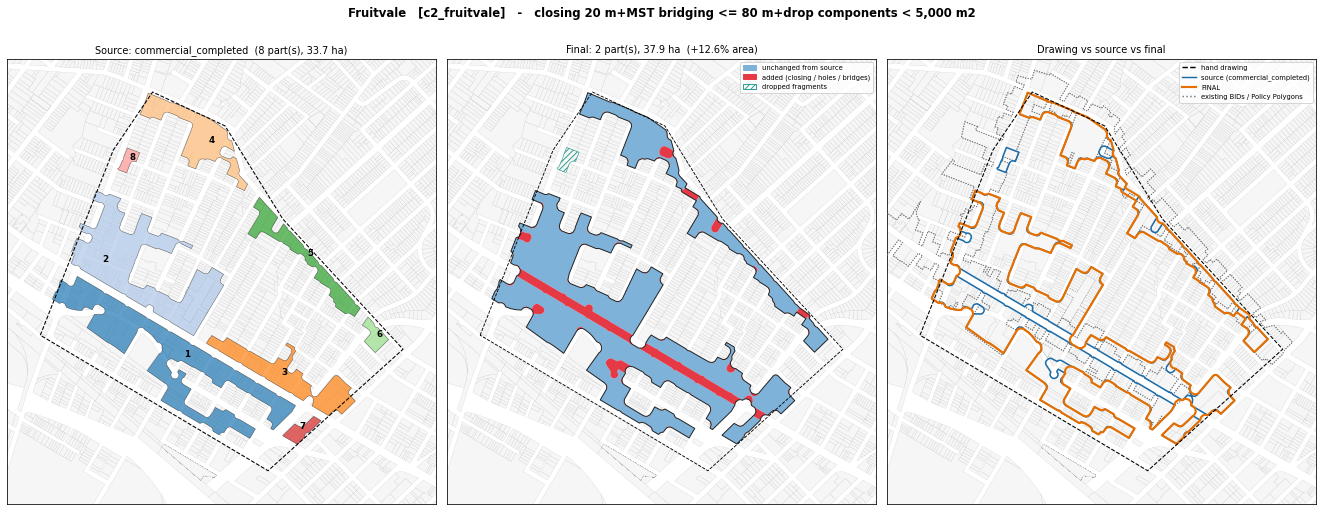

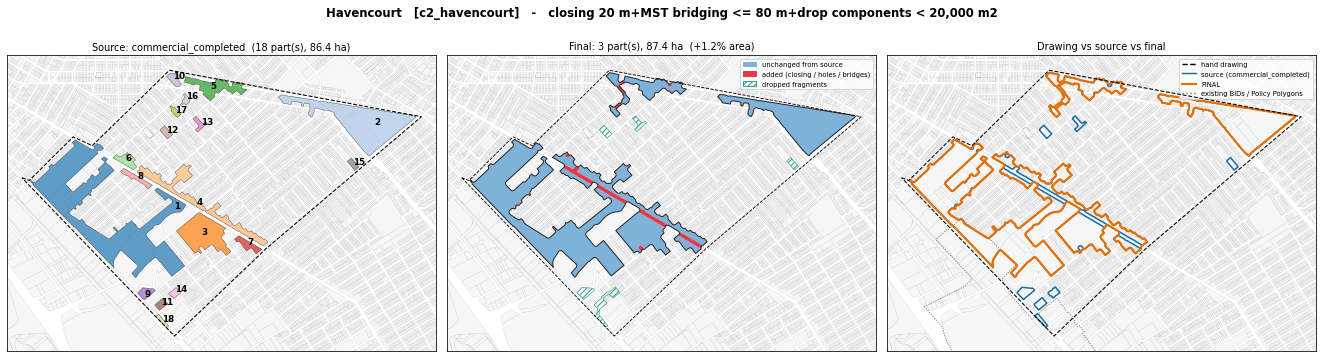

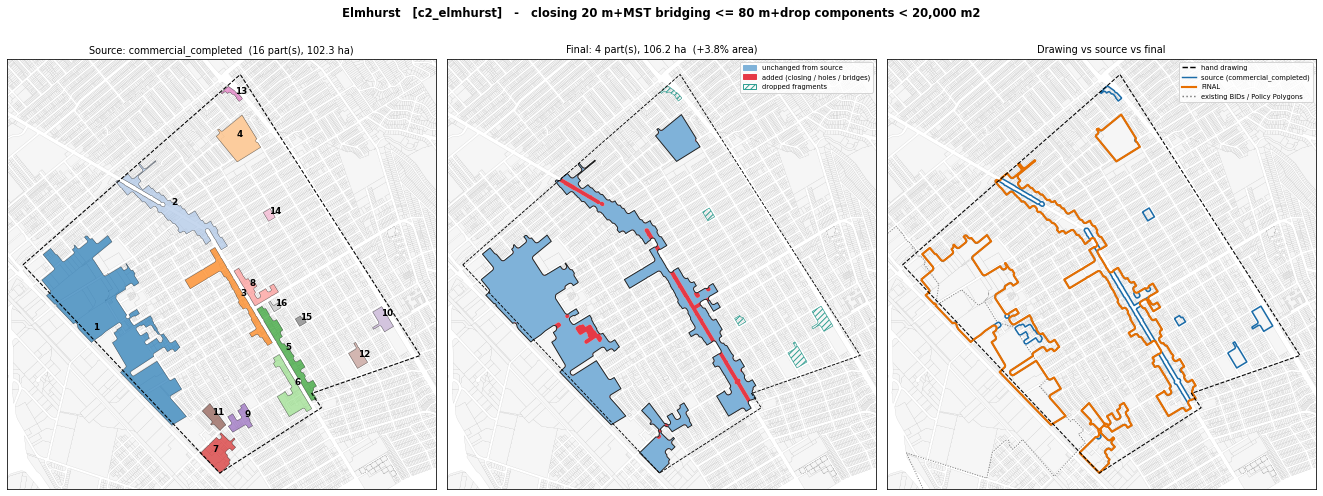

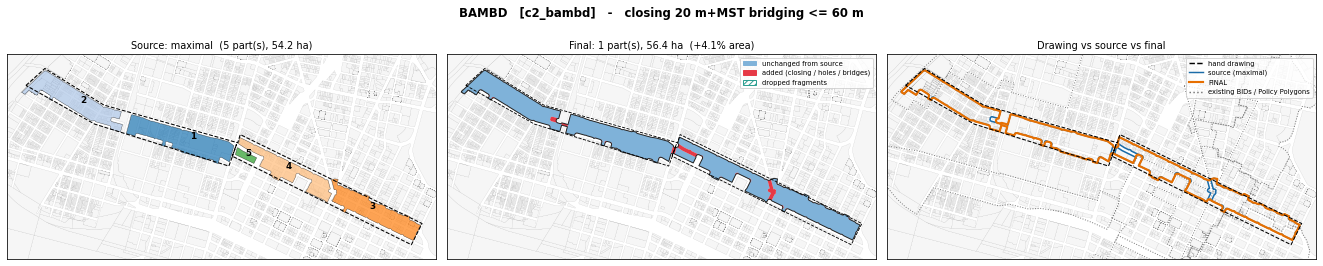

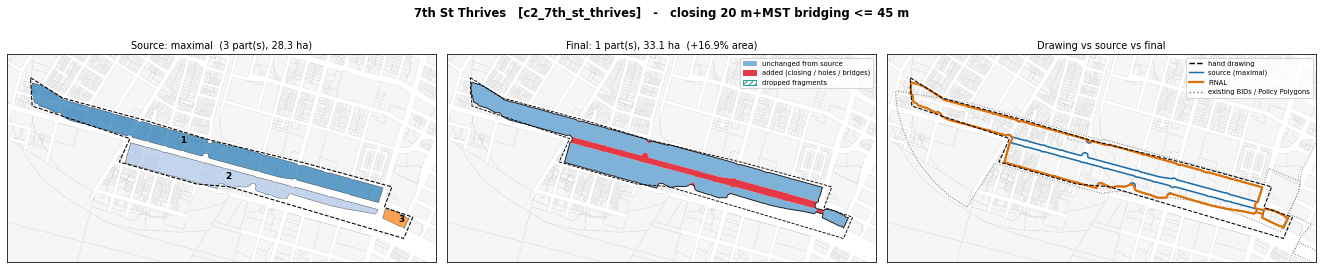

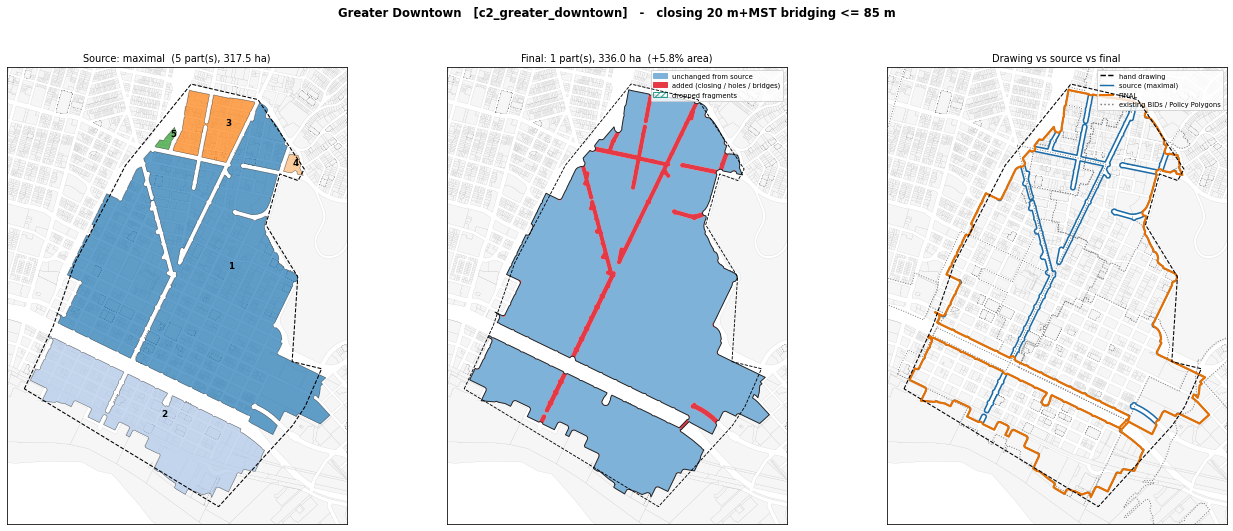

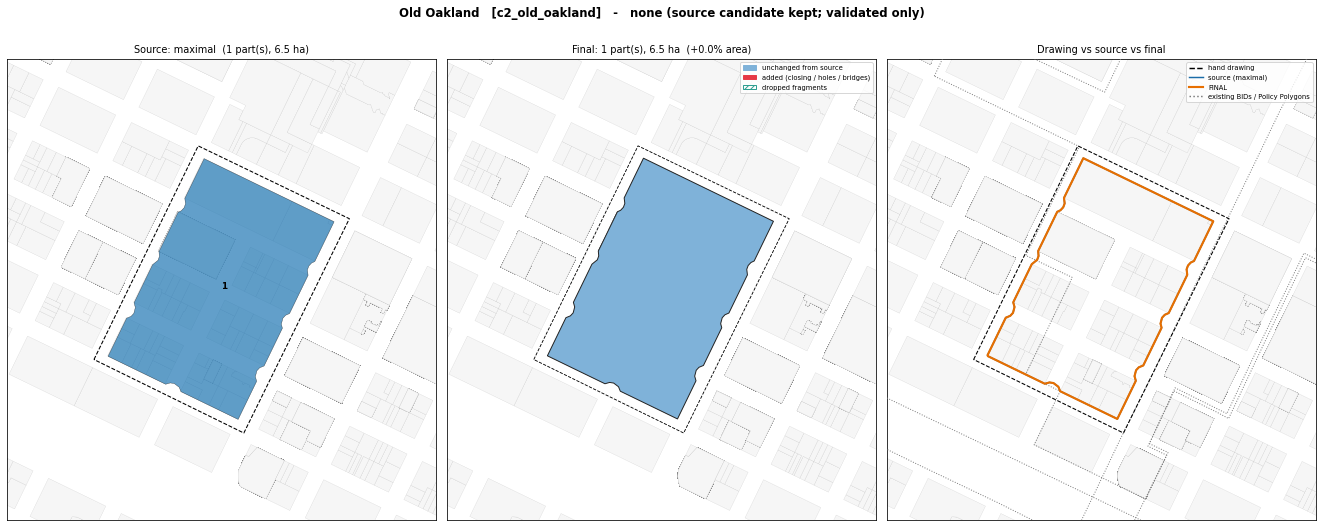

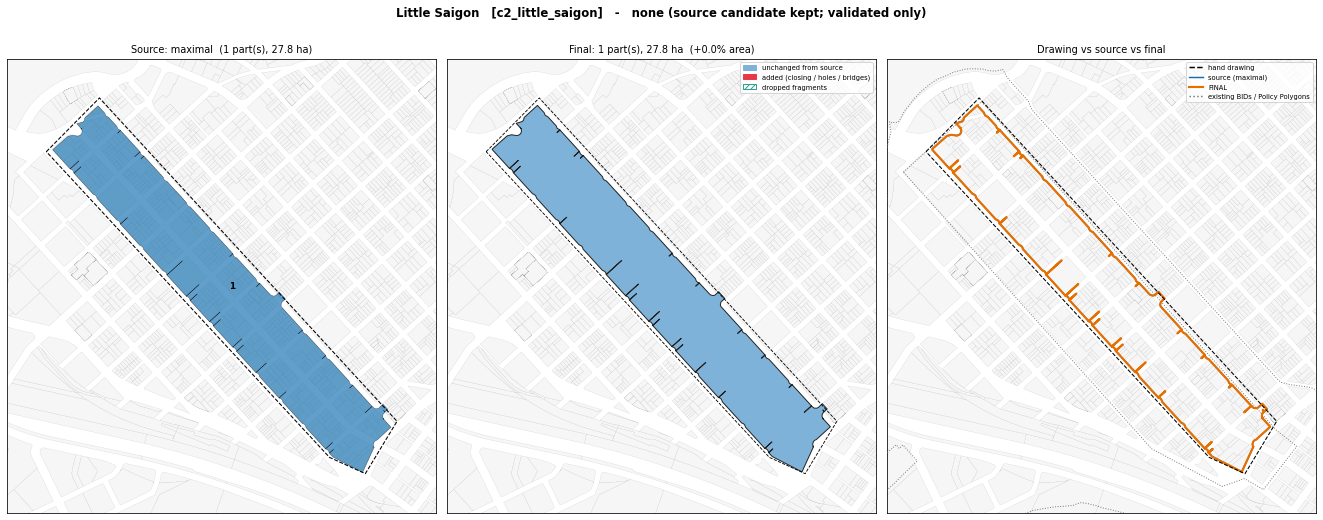

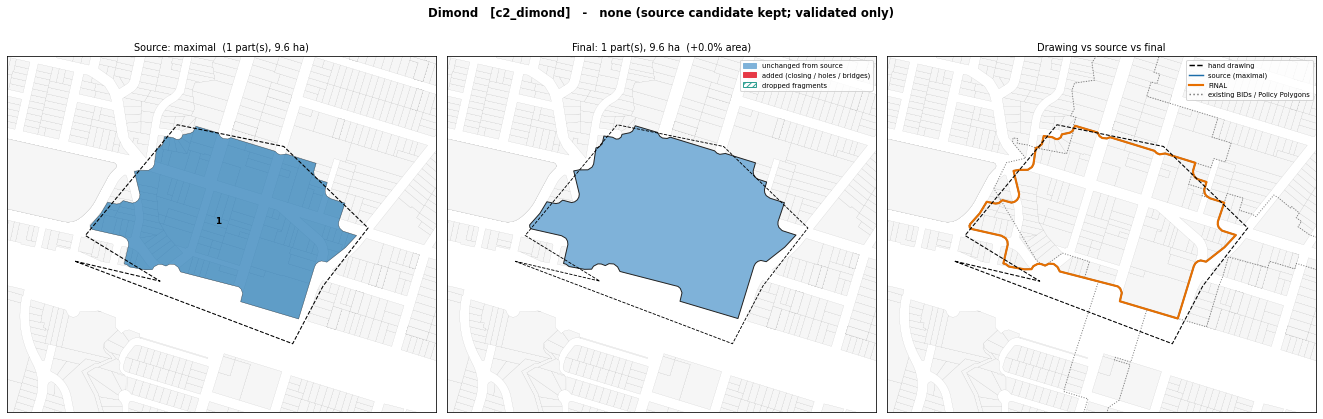

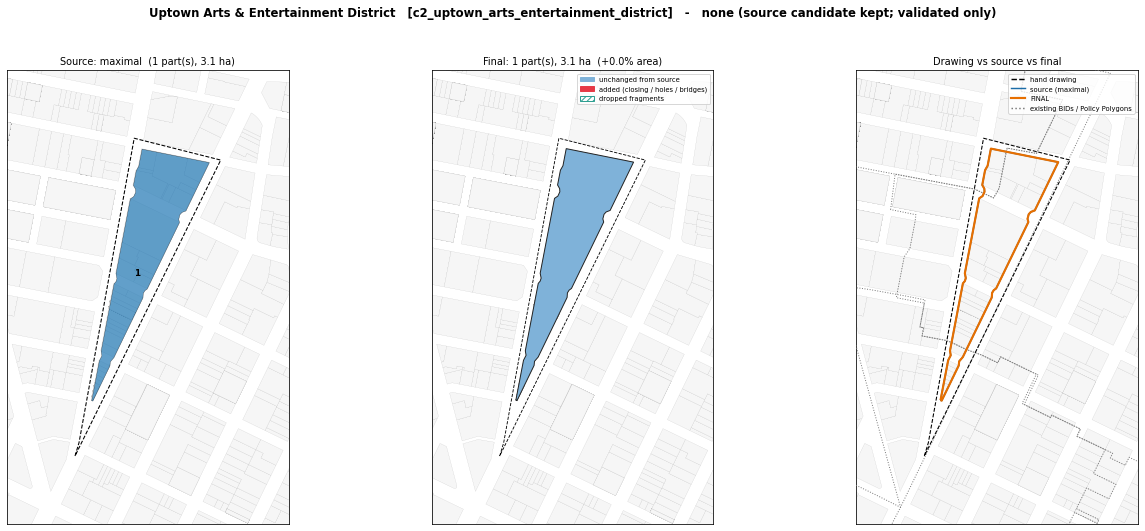

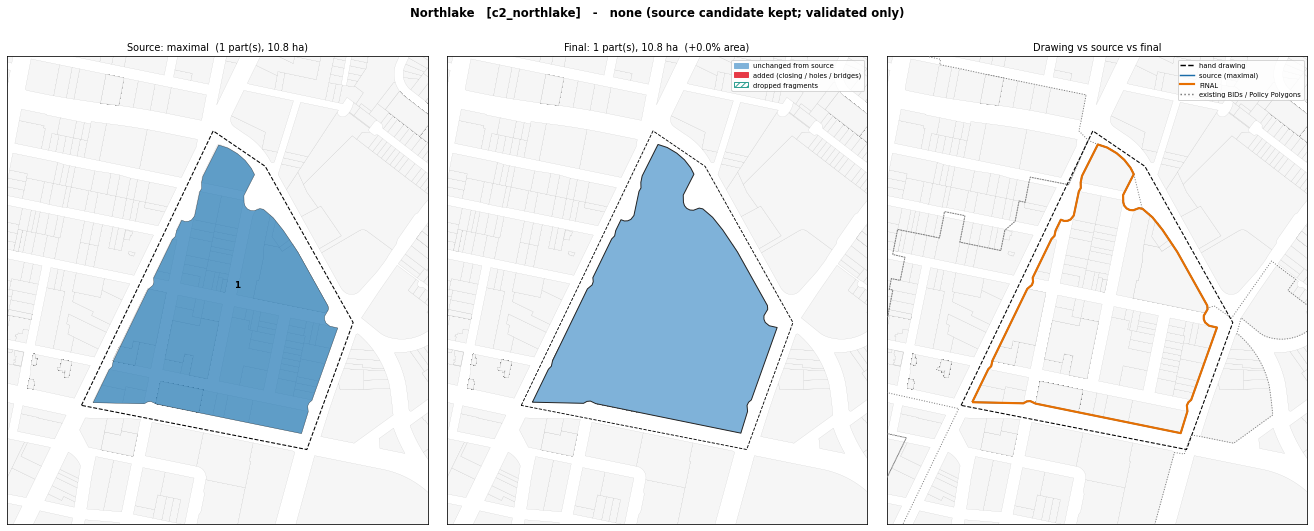

In [25]:
bids_ref = gpd.read_file(BIDS_SHP).to_crs(CRS_METRIC)
policy_ref = gpd.read_file(POLICY_SHP).to_crs(CRS_METRIC)
ref_geoms = list(bids_ref.geometry) + list(policy_ref.geometry)
def draw_parcels(ax, geoms, fc, ec=COL_PARCEL_EDGE, lw=0.2, alpha=1.0):
    if len(geoms):
        gpd.GeoSeries(geoms, crs=CRS_METRIC).plot(ax=ax, facecolor=fc, edgecolor=ec, linewidth=lw, alpha=alpha)

def outline(ax, geom, color, lw=1.6, ls="-", zorder=5):
    if not geom.is_empty:
        gpd.GeoSeries([geom], crs=CRS_METRIC).boundary.plot(ax=ax, color=color, linewidth=lw, linestyle=ls, zorder=zorder)

def style(ax, bounds, title):
    ax.set_xlim(bounds[0], bounds[2]); ax.set_ylim(bounds[1], bounds[3])
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=10)

def plot_final(cid):
    res, draw, rec = final_store[cid], DRAW[cid], final_summary.set_index("corridor_id").loc[cid]
    # frame on the drawing and everything we produced
    bounds = shapely.union_all([draw, res["source"], res["final"]]).buffer(MAP_PAD_M / 2).bounds
    w, h = bounds[2] - bounds[0], bounds[3] - bounds[1]
    panel_h = float(np.clip(6.3 * h / w, 2.8, 6.8))
    fig, axes = plt.subplots(1, 3, figsize=(19, panel_h + 0.9), dpi=MAP_DPI)
    near = parcels_geoms[tree_parcels.query(shapely.box(*bounds), predicate="intersects")]
    for ax in axes:
        draw_parcels(ax, near, "#f6f6f6", lw=0.1)
    # 1 -- source candidate parts
    ax = axes[0]
    for i, p in enumerate(parts_sorted(res["source"])):
        gpd.GeoSeries([p], crs=CRS_METRIC).plot(ax=ax, facecolor=plt.cm.tab20(i % 20), alpha=0.7, edgecolor="k", linewidth=0.4)
        pt = p.representative_point(); ax.annotate(str(i + 1), (pt.x, pt.y), fontsize=9, weight="bold")
    outline(ax, draw, "k", lw=1.1, ls="--")
    style(ax, bounds, f"Source: {rec.source_method}  ({rec.n_parts_source} part(s), {rec.source_area_m2/1e4:,.1f} ha)")
    # 2 -- final vs source
    ax = axes[1]
    added = res["final"].difference(res["source"])
    gpd.GeoSeries(polys_of(res["source"].intersection(res["final"])), crs=CRS_METRIC).plot(ax=ax, facecolor="#7fb2d9", edgecolor="none")
    if not added.is_empty:
        gpd.GeoSeries(polys_of(added), crs=CRS_METRIC).plot(ax=ax, facecolor="#e63946", edgecolor="none")
    if not res["dropped"].is_empty:
        gpd.GeoSeries(polys_of(res["dropped"]), crs=CRS_METRIC).plot(ax=ax, facecolor="none", edgecolor="#2a9d8f", hatch="////", linewidth=0.6)
    outline(ax, res["final"], "#222222", lw=1.0); outline(ax, draw, "k", lw=0.9, ls="--", zorder=6)
    ax.legend(handles=[Patch(color="#7fb2d9", label="unchanged from source"), Patch(color="#e63946", label="added (closing / holes / bridges)"),
                       Patch(facecolor="none", edgecolor="#2a9d8f", hatch="////", label="dropped fragments")], loc="upper right", fontsize=7)
    style(ax, bounds, f"Final: {rec.n_parts_final} part(s), {rec.final_area_m2/1e4:,.1f} ha  ({rec.pct_area_change:+.1f}% area)")
    # 3 -- overlay
    ax = axes[2]
    box = shapely.box(*bounds)
    for g in ref_geoms:
        if g.intersects(box):
            outline(ax, g, "#777777", lw=1.0, ls=":", zorder=3)
    outline(ax, res["source"], "#1b6ca8", lw=1.6); outline(ax, res["final"], "#e76f00", lw=2.2); outline(ax, draw, "k", lw=1.1, ls="--", zorder=6)
    ax.legend(handles=[Line2D([], [], color="k", ls="--", label="hand drawing"), Line2D([], [], color="#1b6ca8", label=f"source ({rec.source_method})"),
                       Line2D([], [], color="#e76f00", lw=2.2, label="FINAL"), Line2D([], [], color="#777", ls=":", label="existing BIDs / Policy Polygons")],
              loc="upper right", fontsize=7)
    style(ax, bounds, "Drawing vs source vs final")
    fig.suptitle(f"{LABEL[cid]}   [{cid}]   -   {rec.continuity_method}", fontsize=12, weight="bold")
    plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

review_order = work_ids + [c for c in corridors.corridor_id if c not in work_ids]
for cid in tqdm(review_order, desc="Final maps"):
    plot_final(cid)

### All final corridors together

Overlaps between corridors (e.g. inside Greater Downtown) are intentionally retained.

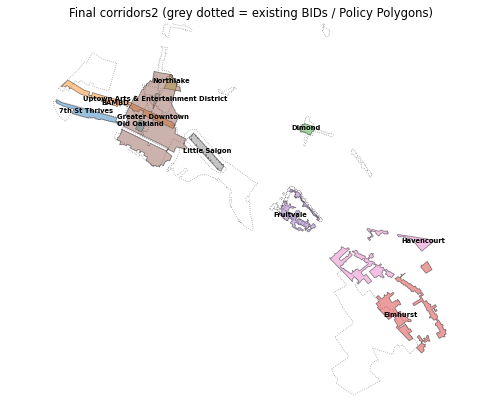

Structural yardstick: median area / parts / vertices per feature


,area_ha,n_parts,n_vertices
layer,,,
OAK_BIDs,38.700,1.000,257.000
Policy_Polygons,52.800,1.000,116.000
corridors2_final,33.100,1.000,184.000


In [26]:
fig, ax = plt.subplots(figsize=(9, 11), dpi=MAP_DPI)
for g in ref_geoms:
    outline(ax, g, "#999999", lw=0.8, ls=":", zorder=1)
final_gdf.plot(ax=ax, column="corridor_id", cmap="tab20", alpha=0.45, edgecolor="k", linewidth=0.8, zorder=2)
for r in final_gdf.itertuples():
    p = r.geometry.representative_point(); ax.annotate(LABEL[r.corridor_id], (p.x, p.y), fontsize=7, ha="center", weight="bold")
b = final_gdf.total_bounds; ax.set_xlim(b[0] - 1500, b[2] + 1500); ax.set_ylim(b[1] - 1500, b[3] + 1500)
ax.set_aspect("equal"); ax.axis("off"); ax.set_title("Final corridors2 (grey dotted = existing BIDs / Policy Polygons)")
plt.show()

def ref_stats(gdf, name_col, label):
    return pd.DataFrame({"layer": label, "area_ha": gdf.area.values / 1e4, "n_parts": [n_parts(g) for g in gdf.geometry],
                         "n_vertices": shapely.get_num_coordinates(gdf.geometry.values)})
cmp = pd.concat([ref_stats(bids_ref, "BID", "OAK_BIDs"), ref_stats(policy_ref, "PP_Name", "Policy_Polygons"),
                 ref_stats(final_gdf, "corridor_name", "corridors2_final")])
print("Structural yardstick: median area / parts / vertices per feature")
display(cmp.groupby("layer")[["area_ha", "n_parts", "n_vertices"]].median().round(1))

**Takeaways -- final maps**

* **BAMBD / 7th St Thrives:** the added material (red) is limited to the street gaps and short links between the existing pieces; the outer boundary follows the maximal footprint.
* **Greater Downtown:** the street grid between the parcel blocks is filled, but the very wide band that separates the northern and southern block groups is **not** filled; the two halves are joined only by a narrow street-width link, so the polygon does not swallow that corridor. Overlaps with Old Oakland, Uptown, Northlake and BAMBD are retained.
* **Fruitvale:** the International Blvd axis and its facing blocks become one corridor; the NE commercial strip is linked to it; one isolated piece was dropped.
* **Havencourt / Elmhurst:** the main commercial clusters and the long central strips are joined into larger contiguous corridors, but isolated patches farther than the bridging limit remain separate parts (3 and 4 parts) rather than being joined across residential blocks.
* The final polygons are similar in scale and vertex count to the BIDs and Policy Polygons (median 33 ha / 184 vertices vs 39 / 257 and 53 / 116).

# Section 15 -- Export of the Final Layer

`corridors2_final.gpkg` (layer `corridors`) holds all 11 final features in `CRS_EXPORT`; areas are square metres computed in `CRS_METRIC`.

**Parcel provenance.** `corridors2_final_selected_parcels.gpkg` is also written: one row per parcel that contributes to a final corridor. It is a filtered
subset of the candidate-stage QA file (only the parcels of the chosen source method that lie in the final polygon), so it is partly redundant, but it is small enough and makes each final corridor
traceable to its parcels without having to re-apply the per-corridor choice by hand.

In [27]:
FINAL_DIR.mkdir(parents=True, exist_ok=True)
fcols = ["corridor_id", "corridor_name", "source_method", "continuity_method", "n_source_parcels", "n_dropped_parcels", "closing_distance_m",
         "bridge_max_gap_m", "n_bridges", "n_components_dropped", "n_parts_source", "n_parts_final", "source_area_m2", "final_area_m2",
         "pct_area_change", "pct_final_in_drawing", "pct_drawing_covered", "notes", "geometry"]
out_final = final_gdf[fcols].rename(columns={"n_parts_source": "n_parts_before", "n_parts_final": "n_parts_after"}).to_crs(CRS_EXPORT)
out_final["geometry"] = [polygonal_only(g) for g in shapely.make_valid(out_final.geometry.values)]
assert out_final.is_valid.all() and out_final.geom_type.isin(["Polygon", "MultiPolygon"]).all() and not out_final.is_empty.any()
out_final.to_file(FINAL_GPKG, layer=FINAL_LAYER, driver="GPKG")

fp = final_selected.copy()
fp["parcel_id"] = fp.APN
fp["corridor_name"] = fp.corridor_id.map(NAME)
fp["geometry"] = parcels_geoms[fp.pos.values]
fp = gpd.GeoDataFrame(fp, geometry="geometry", crs=CRS_METRIC)
fp = fp.dissolve(by=["corridor_id", "corridor_name", "source_method", "parcel_id"], as_index=False,
                 aggfunc={"ratio": "first", "commercial": "first"})
fp = fp.rename(columns={"ratio": "parcel_overlap_ratio", "commercial": "commercial_or_business_flag"})
fp = fp[["corridor_id", "corridor_name", "source_method", "parcel_id", "parcel_overlap_ratio", "commercial_or_business_flag", "geometry"]].to_crs(CRS_EXPORT)
est_mb = len(fp) * 0.0004
if est_mb < SELECTED_PARCELS_MAX_MB:
    fp.to_file(FINAL_SELECTED_PARCELS_GPKG, layer=FINAL_SELECTED_LAYER, driver="GPKG")
    print(f"final selected parcels: {len(fp):,} rows -> {FINAL_SELECTED_PARCELS_GPKG.relative_to(ROOT)} ({FINAL_SELECTED_PARCELS_GPKG.stat().st_size/1e6:.1f} MB)")
else:
    print(f"final selected parcels skipped (estimated {est_mb:.0f} MB)")

chk = gpd.read_file(FINAL_GPKG, layer=FINAL_LAYER)
print(f"{FINAL_GPKG.relative_to(ROOT)}: {len(chk)} features | CRS {chk.crs.to_string()} | valid {bool(chk.is_valid.all())} | "
      f"types {chk.geom_type.value_counts().to_dict()} | {FINAL_GPKG.stat().st_size/1e6:.2f} MB")
display(chk.drop(columns="geometry")[["corridor_id", "source_method", "continuity_method", "n_source_parcels", "n_parts_before", "n_parts_after"]])

final selected parcels: 9,680 rows -> data/corridors/corridors2/corridors2_final_selected_parcels.gpkg (4.9 MB)
data/corridors/corridors2/corridors2_final.gpkg: 11 features | CRS EPSG:4326 | valid True | types {'MultiPolygon': 11} | 0.16 MB


,corridor_id,source_method,continuity_method,n_source_parcels,n_parts_before,n_parts_after
0,c2_old_oakland,maximal,none (source candidate kept; validated only),105,1,1
1,c2_little_saigon,maximal,none (source candidate kept; validated only),377,1,1
2,c2_fruitvale,commercial_completed,closing 20 m+MST bridging <= 80 m+drop compone...,385,8,2
3,c2_dimond,maximal,none (source candidate kept; validated only),111,1,1
4,c2_havencourt,commercial_completed,closing 20 m+MST bridging <= 80 m+drop compone...,292,18,3
5,c2_elmhurst,commercial_completed,closing 20 m+MST bridging <= 80 m+drop compone...,476,16,4
6,c2_uptown_arts_entertainment_district,maximal,none (source candidate kept; validated only),72,1,1
7,c2_northlake,maximal,none (source candidate kept; validated only),354,1,1
8,c2_bambd,maximal,closing 20 m+MST bridging <= 60 m,979,5,1
9,c2_7th_st_thrives,maximal,closing 20 m+MST bridging <= 45 m,287,3,1


## Final Corridors2

**Number of final corridors:** 11, in `data/corridors/corridors2/corridors2_final.gpkg` (layer `corridors`, EPSG:4326, all valid).

**Source method by corridor**

| Corridor | Source | Treatment | Parts (source -> final) |
|---|---|---|---|
| BAMBD | maximal | closing 20 m + bridging <= 60 m | 5 -> 1 |
| 7th St Thrives | maximal | closing 20 m + bridging <= 45 m | 3 -> 1 |
| Greater Downtown | maximal | closing 20 m + bridging <= 85 m | 5 -> 1 |
| Old Oakland | maximal | unchanged | 1 -> 1 |
| Uptown Arts & Entertainment District | maximal | unchanged | 1 -> 1 |
| Northlake | maximal | unchanged | 1 -> 1 |
| Little Saigon | maximal | unchanged | 1 -> 1 |
| Dimond | maximal | unchanged | 1 -> 1 |
| Fruitvale | commercial_completed | closing 20 m + bridging <= 80 m + drop components < 0.5 ha | 8 -> 2 |
| Havencourt | commercial_completed | closing 20 m + bridging <= 80 m + drop components < 2 ha | 18 -> 3 |
| Elmhurst | commercial_completed | closing 20 m + bridging <= 80 m + drop components < 2 ha | 16 -> 4 |

* **Continuity fixing:** BAMBD, 7th St Thrives, Greater Downtown (all now one Polygon), and Fruitvale, Havencourt, Elmhurst (fragmentation reduced).
* **Preserved unchanged** (validated only, 0.0% area change): Old Oakland, Uptown Arts, Northlake, Little Saigon, Dimond.
* **Used `commercial_completed` instead of `maximal`:** Fruitvale, Havencourt, Elmhurst. No maximal parcels were added to them.
* **Remaining MultiPolygons:** Fruitvale (2 parts), Havencourt (3) and Elmhurst (4). They were not forced together because the remaining gaps (roughly 90-250+ m for Havencourt/Elmhurst, 159 m for Fruitvale) would require bridging several residential blocks. Note that the GeoPackage stores every feature with a multi-polygon geometry type, but only these three actually have more than one part (`n_parts_after`).

**Inspect manually in QGIS**
1. **Greater Downtown:** the narrow link across the wide band between the northern and southern block groups (the only bridge there), and whether you want that band included or left out.
2. **Havencourt and Elmhurst:** the isolated parts that stay separate (e.g. the NE strip and top cluster in Havencourt; the NE block and the southern cluster in Elmhurst) and the dropped small components (their parcels are excluded from the selected-parcels file; counts in `n_dropped_parcels`). Also confirm these two drawings are really meant as whole districts.
3. **7th St Thrives** (+16.9% area) and **Fruitvale** (+12.6%): confirm that the filled street between facing blocks is what you want.
4. **BAMBD:** the 52 m link where the source drawing is split.
5. Bridges are 20 m-wide strips with rounded ends along the shortest line between components; check the few places where they run through a block rather than along a street.

**Final output:** `data/corridors/corridors2/corridors2_final.gpkg` (corridor_id, corridor_name, source_method, continuity_method, n_source_parcels, plus closing/bridging settings, part counts, areas and notes). Parcel provenance is in `data/corridors/corridors2/corridors2_final_selected_parcels.gpkg` (one row per parcel x corridor). The candidate GeoPackages from the previous stage are still in `data/corridors/corridors2_candidates/`.